<a href="https://colab.research.google.com/github/turayusa/homework/blob/main/DX799_Week5_Diabetes_Readmission_SVM_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Boston University
## Faculty of Computing & Data Sciences
### Online Master of Science in Data Science

# DX799: Module C – Data Science Capstone

## Week 5: Support Vector Machines, Kernel Trick, and Regularization

**Student:** Abdul Karim Turay

**Dataset:** Diabetes 130-US Hospitals (1999–2008)

**Project:** Predicting Diabetes-Related Hospital Readmission Using Support Vector Machines

**Date:** October 2026



# Table of Contents

## 1. Introduction and Research Objectives
- 1.1 Research Objective
- 1.2 Research Question
- 1.3 Evaluation Strategy

## 2. Dataset Loading and Preparation
- 2.1 Import Required Libraries
- 2.2 Load the Diabetes Hospitalization Dataset
- 2.3 Data Cleaning and Feature Selection
- 2.4 Define Predictor Variables and Target Outcome
- 2.5 Training and Testing Data

## 3. Exploratory Data Analysis (EDA)
- 3.1 Dataset Characteristics
- 3.2 Readmission Class Distribution
- 3.3 Feature Scaling and Preprocessing

## 4. Baseline Support Vector Machine
- 4.1 Linear SVM Model
- 4.2 Model Training and Prediction
- 4.3 Baseline Performance Evaluation

## 5. Kernel Trick and Nonlinear SVM
- 5.1 Radial Basis Function (RBF) Kernel
- 5.2 Polynomial Kernel
- 5.3 Kernel Performance Comparison

## 6. Regularization and Hyperparameter Tuning
- 6.1 Regularization Parameter (C)
- 6.2 Kernel Parameter (Gamma)
- 6.3 Cross-Validation and Hyperparameter Selection

## 7. Model Evaluation and Comparison
- 7.1 Accuracy, Precision, Recall, and F1-Score
- 7.2 Confusion Matrix
- 7.3 ROC Curve and ROC-AUC
- 7.4 Comparison With Week 4 Logistic Regression

## 8. Overfitting and Generalization Assessment
- 8.1 Training and Validation Performance
- 8.2 Overfitting Prevention Strategies

## 9. Discussion and Interpretation
- 9.1 Expected and Unexpected Findings
- 9.2 Clinical and Public Health Implications
- 9.3 Model Limitations

## 10. Conclusion

## 11. References

## 12. Artificial Intelligence (AI) Use Disclosure



# 1. Introduction and Research Objectives

## 1.1 Research Objective

The objective of this analysis is to apply Support Vector Machines (SVMs) to predict diabetes-related hospital readmission using patient-level clinical and demographic information from the Diabetes 130-US Hospitals dataset (Clore et al., 2014).

This analysis examines linear and nonlinear SVM classifiers, the kernel trick, and regularization to evaluate predictive performance and model generalization.

## 1.2 Research Question

Can Support Vector Machines improve diabetes-related hospital readmission prediction compared with the logistic regression models evaluated in Week 4?

## 1.3 Evaluation Strategy

Model performance will be evaluated using accuracy, precision, recall, F1-score, and ROC-AUC. Particular attention will be given to recall because identifying patients at risk of readmission is important for healthcare planning.

Cross-validation will be used for hyperparameter selection, and the reserved test set will be used for final model evaluation.



# 1. Introduction and Research Objectives

## 1.1 Research Objective

The objective of this analysis is to apply Support Vector Machines (SVMs) to predict diabetes-related hospital readmission using patient-level clinical and demographic information from the Diabetes 130-US Hospitals dataset (Clore et al., 2014).

This analysis examines linear and nonlinear SVM classifiers, the kernel trick, and regularization to evaluate predictive performance and model generalization.

## 1.2 Research Question

Can Support Vector Machines improve diabetes-related hospital readmission prediction compared with the logistic regression models evaluated in Week 4?

## 1.3 Evaluation Strategy

Model performance will be evaluated using accuracy, precision, recall, F1-score, and ROC-AUC. Particular attention will be given to recall because identifying patients at risk of readmission is important for healthcare planning.

Cross-validation will be used for hyperparameter selection, and the reserved test set will be used for final model evaluation.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("Week 5 SVM libraries imported successfully.")


Week 5 SVM libraries imported successfully.



### Analysis and Interpretation

The required Python libraries were imported to support the implementation of Support Vector Machine classifiers. The selected tools provide the necessary functionality for preprocessing, feature scaling, linear and nonlinear kernel modeling, hyperparameter tuning, and performance evaluation. Using preprocessing pipelines will help ensure that transformations are fitted only on training data, reducing the risk of data leakage during model development.



## 2.2 Load the Diabetes Hospitalization Dataset

### Objective

The objective of this step is to load the Diabetes 130-US Hospitals dataset (1999–2008) into Google Colab and examine its structure before preparing the data for Support Vector Machine modeling.

### Code Explanation

The code allows the dataset to be uploaded from my computer into Google Colab. Pandas is used to read the CSV file and display the first five observations, dataset dimensions, column names, and data types.

This preliminary inspection helps confirm that the dataset has been loaded correctly and identifies the variables available for predicting hospital readmission.


In [2]:

from google.colab import files
from io import BytesIO

uploaded = files.upload()

if not uploaded:
    raise ValueError("No dataset was uploaded.")

filename = next(iter(uploaded))

df = pd.read_csv(
    BytesIO(uploaded[filename]),
    low_memory=False
)

print("Dataset loaded:", filename)
print("\nDataset dimensions:", df.shape)

print("\nFirst five observations:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))


Saving diabetic_data.csv to diabetic_data (1).csv
Dataset loaded: diabetic_data (1).csv

Dataset dimensions: (101766, 50)

First five observations:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Column names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Data types:


,Data Type
encounter_id,int64
patient_nbr,int64
race,object
gender,object
age,object
weight,object
admission_type_id,int64
discharge_disposition_id,int64
admission_source_id,int64
time_in_hospital,int64



### 2.2 Analysis and Interpretation

The Diabetes 130-US Hospitals dataset was successfully loaded into Google Colab, containing 101,766 hospital encounters and 50 variables. The dataset includes patient demographics, hospital admission characteristics, diagnoses, laboratory procedures, medication information, length of hospital stay, and readmission status.

The preliminary inspection identified both numerical and categorical variables, indicating that appropriate preprocessing and feature encoding will be required before applying Support Vector Machine models. The `readmitted` variable represents the outcome of interest for predicting diabetes-related hospital readmission.

The dataset provides a foundation for examining whether linear and nonlinear Support Vector Machine classifiers can identify patterns associated with hospital readmission. Further data cleaning and feature selection are necessary to address missing values, exclude inappropriate predictors, and prepare the dataset for model development.


In [3]:

# 2.3 Data Cleaning and Feature Selection

# Preserve the original dataset
df_clean = df.copy()

# Convert question marks into missing values
df_clean = df_clean.replace("?", np.nan)

# Examine missing values
missing_count = df_clean.isna().sum()

missing_percent = (
    missing_count / len(df_clean)
) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print("Original dataset dimensions:", df.shape)
print("Working dataset dimensions:", df_clean.shape)

print("\nMissing values by variable:")
display(missing_summary.round(2))

# Check duplicate encounters
duplicate_encounters = df_clean[
    "encounter_id"
].duplicated().sum()

print("\nDuplicate encounter IDs:",
      duplicate_encounters)

# Examine the readmission outcome
print("\nReadmission distribution:")

readmission_summary = pd.DataFrame({
    "Count": df_clean["readmitted"].value_counts(),
    "Percentage": (
        df_clean["readmitted"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(readmission_summary)

# Confirm current dataset dimensions
print("\nDataset dimensions before cleaning decisions:",
      df_clean.shape)


Original dataset dimensions: (101766, 50)
Working dataset dimensions: (101766, 50)

Missing values by variable:


,Missing Count,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02



Duplicate encounter IDs: 0

Readmission distribution:


,Count,Percentage
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16



Dataset dimensions before cleaning decisions: (101766, 50)



### 2.3 Analysis and Interpretation

The data quality assessment identified 101,766 hospital encounters and 50 variables, with no duplicate encounter identifiers. Several variables contained substantial missing information, including weight (96.86%), maximum glucose serum (94.75%), A1C results (83.28%), medical specialty (49.08%), and payer code (39.56%). In contrast, race and the three diagnosis variables had relatively low percentages of missing values.

The readmission outcome consisted of three categories: NO (53.91%), >30 days (34.93%), and <30 days (11.16%). These findings indicate an unequal distribution across readmission categories, which should be considered when developing and evaluating classification models.

The high proportion of missing values in certain variables suggests that excluding them may be more appropriate than attempting extensive imputation. Variables with lower missingness may be retained using suitable preprocessing methods. No observations were removed during this assessment.

These findings provide the basis for selecting appropriate predictors, defining the binary readmission outcome consistently with Week 4, and preparing the dataset for Support Vector Machine modeling.


In [4]:

# 2.3 Data Cleaning and Feature Selection
# Final cleaning and predictor selection

# Preserve the assessed dataset
df_model = df_clean.copy()

# Identify columns with more than 80% missing values
high_missing_cols = df_model.columns[
    df_model.isna().mean() > 0.80
].tolist()

# Remove high-missingness variables and identifiers
df_model = df_model.drop(
    columns=high_missing_cols + [
        "encounter_id", "patient_nbr"
    ],
    errors="ignore"
)

# Select predictors
selected_features = [
    "race",
    "gender",
    "age",
    "admission_type_id",
    "admission_source_id",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "change",
    "diabetesMed"
]

# Retain selected features and outcome
df_model = df_model[
    selected_features + ["readmitted"]
].copy()

print("Excluded high-missingness variables:")
print(high_missing_cols)

print("\nOriginal dataset:", df.shape)
print("Modeling dataset:", df_model.shape)

print("\nNumber of predictors:", len(selected_features))

print("\nMissing values in selected variables:")
display(
    df_model.isna().sum().to_frame("Missing Count")
)

print("\nFirst five observations:")
display(df_model.head())


Excluded high-missingness variables:
['weight', 'max_glu_serum', 'A1Cresult']

Original dataset: (101766, 50)
Modeling dataset: (101766, 16)

Number of predictors: 15

Missing values in selected variables:


,Missing Count
race,2273
gender,0
age,0
admission_type_id,0
admission_source_id,0
time_in_hospital,0
num_lab_procedures,0
num_procedures,0
num_medications,0
number_outpatient,0



First five observations:


,race,gender,age,admission_type_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),6,1,1,41,0,1,0,0,0,1,No,No,NO
1,Caucasian,Female,[10-20),1,7,3,59,0,18,0,0,0,9,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),1,7,2,11,5,13,2,0,1,6,No,Yes,NO
3,Caucasian,Male,[30-40),1,7,2,44,1,16,0,0,0,7,Ch,Yes,NO
4,Caucasian,Male,[40-50),1,7,1,51,0,8,0,0,0,5,Ch,Yes,NO



### 2.3 Analysis and Interpretation

Following the data quality assessment, the Diabetes 130-US Hospitals dataset was prepared for Support Vector Machine modeling. Three variables with more than 80% missing values were excluded: weight, maximum glucose serum, and A1C results. Patient and encounter identifiers were also excluded because they do not represent appropriate clinical predictors.

The resulting modeling dataset retained 101,766 hospital encounters and 16 variables, consisting of 15 demographic, clinical, and healthcare utilization predictors and one readmission outcome.

Among the selected variables, race contained 2,273 missing observations, while the remaining predictors and readmission outcome contained no missing values. These missing values will be addressed through appropriate preprocessing fitted to the training data.

The cleaning process preserved all hospital encounters and established a consistent dataset for subsequent Support Vector Machine modeling. The selected variables provide information about patient characteristics, hospitalization, treatment, and previous healthcare utilization that may contribute to predicting readmission.



## 2.4 Define Predictor Variables and Target Outcome

### Objective

The objective of this step is to define the predictor variables and create a binary readmission outcome for Support Vector Machine classification.

### Code Explanation

The code converts the original readmission categories into a binary outcome:

- 1 = Hospital readmission within 30 days (<30).
- 0 = No readmission within 30 days (NO or >30).

The selected demographic, clinical, and healthcare utilization variables are assigned to the predictor matrix (X), while the binary readmission outcome is assigned to the target variable (y).

The code then displays the predictor dimensions and binary outcome distribution to verify that the classification problem has been defined correctly.


In [5]:

# 2.4 Define Predictor Variables and Target Outcome

# Create binary readmission outcome
df_model["readmitted_binary"] = (
    df_model["readmitted"] == "<30"
).astype(int)

# Define predictor variables
X = df_model[selected_features].copy()

# Define target variable
y = df_model["readmitted_binary"].copy()

# Display dimensions
print("Predictor matrix dimensions:", X.shape)
print("Target variable dimensions:", y.shape)

# Display binary outcome distribution
binary_summary = pd.DataFrame({
    "Count": y.value_counts().sort_index(),
    "Percentage": (
        y.value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
})

binary_summary.index = [
    "0 = No readmission within 30 days",
    "1 = Readmission within 30 days"
]

print("\nBinary readmission distribution:")
display(binary_summary)

print("\nNumber of predictors:", X.shape[1])
print("Missing predictor values:", X.isna().sum().sum())
print("Missing target values:", y.isna().sum())


Predictor matrix dimensions: (101766, 15)
Target variable dimensions: (101766,)

Binary readmission distribution:


,Count,Percentage
0 = No readmission within 30 days,90409,88.84
1 = Readmission within 30 days,11357,11.16



Number of predictors: 15
Missing predictor values: 2273
Missing target values: 0



### 2.4 Analysis and Interpretation

The binary readmission outcome was successfully created from the original readmission categories. Hospital encounters involving readmission within 30 days were classified as 1, while encounters without readmission within 30 days were classified as 0.

The predictor matrix contained 101,766 observations and 15 variables, while the target variable contained 101,766 observations. Of these, 90,409 encounters (88.84%) were classified as no readmission within 30 days, and 11,357 encounters (11.16%) were classified as readmission within 30 days.

The results indicate a substantial class imbalance, with considerably fewer positive readmission cases. Therefore, accuracy alone may not adequately represent model performance. Precision, recall, F1-score, and ROC-AUC will also be evaluated.

The predictor matrix contained 2,273 missing values, while the target variable contained no missing values. These missing predictor values will be handled through training-fitted preprocessing to reduce the risk of data leakage.



## 2.5 Training and Testing Data

### Objective

The objective of this step is to divide the diabetes hospitalization dataset into training and testing subsets while reducing the risk of data leakage between hospital encounters belonging to the same patient.

### Code Explanation

The code uses patient identifiers to create an 80% training and 20% testing split through group-aware stratification.

This approach aims to preserve the readmission class distribution while ensuring that hospital encounters belonging to the same patient are assigned to only one subset.

The code then examines the number of observations, readmission class proportions, and patient overlap between the training and testing subsets.

The testing dataset will remain reserved for final model evaluation.


In [6]:

# 2.5 Training and Testing Data

from sklearn.model_selection import StratifiedGroupKFold

# Patient identifiers used only for grouping
groups = df_clean.loc[X.index, "patient_nbr"]

# Create approximately 80/20 group-aware split
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Check patient overlap
train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])

patient_overlap = len(
    train_patients.intersection(test_patients)
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining class distribution (%):")
print(
    (y_train.value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nTesting class distribution (%):")
print(
    (y_test.value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nPatients appearing in both sets:",
      patient_overlap)

print("\nTraining predictor dimensions:",
      X_train.shape)

print("Testing predictor dimensions:",
      X_test.shape)


Training observations: 81413
Testing observations: 20353

Training class distribution (%):
readmitted_binary
0    88.92
1    11.08
Name: proportion, dtype: float64

Testing class distribution (%):
readmitted_binary
0    88.53
1    11.47
Name: proportion, dtype: float64

Patients appearing in both sets: 0

Training predictor dimensions: (81413, 15)
Testing predictor dimensions: (20353, 15)



### 2.5 Analysis and Interpretation

The Diabetes 130-US Hospitals dataset was successfully divided into training and testing subsets using patient-grouped stratification. The training dataset contained 81,413 hospital encounters, while the testing dataset contained 20,353 encounters, each with 15 predictor variables.

The training dataset consisted of 88.92% encounters without readmission within 30 days and 11.08% encounters with readmission within 30 days. Similarly, the testing dataset contained 88.53% and 11.47% of the respective classes. These results indicate that the class distributions remained reasonably consistent between the two subsets.

Importantly, no patients appeared in both the training and testing datasets, reducing the risk of information leakage from repeated hospital encounters involving the same patient.

The training dataset will be used for model development and hyperparameter tuning, while the testing dataset will remain reserved for final evaluation. The observed class imbalance will be considered when interpreting classification performance.



# 3. Exploratory Data Analysis (EDA)

## 3.1 Dataset Characteristics

### Objective

The objective of this step is to examine the descriptive characteristics of the selected predictors in the training dataset before developing Support Vector Machine models.

### Code Explanation

The code summarizes the numerical variables using descriptive statistics, including count, mean, standard deviation, minimum, quartiles, and maximum values.

It also identifies categorical predictors and displays their frequency distributions. This assessment provides an understanding of the variables included in the analysis and helps identify differences in measurement scales that may influence Support Vector Machine performance.

The exploratory analysis will focus on the training dataset to preserve the independence of the testing dataset.


In [7]:

# 3.1 Dataset Characteristics

# Identify numerical predictors
numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

# Identify categorical predictors
categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Training dataset dimensions:", X_train.shape)

print("\nNumber of numerical predictors:",
      len(numeric_features))

print("Number of categorical predictors:",
      len(categorical_features))

print("\nNumerical predictor summary:")
display(
    X_train[numeric_features]
    .describe()
    .round(2)
)

print("\nCategorical predictor summary:")
display(
    X_train[categorical_features]
    .describe()
)

print("\nMissing values in training predictors:")
display(
    X_train.isna().sum()
    .to_frame("Missing Count")
)


Training dataset dimensions: (81413, 15)

Number of numerical predictors: 8
Number of categorical predictors: 7

Numerical predictor summary:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,81413.00,81413.00,81413.00,81413.00,81413.00,81413.00,81413.00,81413.00
mean,4.40,43.08,1.34,16.03,0.37,0.20,0.64,7.42
std,2.99,19.69,1.70,8.14,1.27,0.96,1.27,1.94
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
25%,2.00,31.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
max,14.00,132.00,6.00,81.00,42.00,76.00,21.00,16.00



Categorical predictor summary:


,admission_type_id,admission_source_id
count,81413.000000,81413.000000
mean,2.026409,5.750077
std,1.446847,4.066573
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,7.000000
75%,3.000000,7.000000
max,8.000000,25.000000



Missing values in training predictors:


,Missing Count
race,1798
gender,0
age,0
admission_type_id,0
admission_source_id,0
time_in_hospital,0
num_lab_procedures,0
num_procedures,0
num_medications,0
number_outpatient,0



### 3.1 Analysis and Interpretation

The exploratory data analysis examined the characteristics of the 81,413 hospital encounters included in the training dataset. The selected predictors represented patient demographics, admission characteristics, hospital utilization, clinical procedures, medication use, and previous healthcare encounters.

The numerical variables showed differences in their distributions and measurement ranges. Hospital length of stay ranged up to 14 days, while laboratory procedures reached 132 and medication counts reached 81. Previous outpatient, emergency, and inpatient visits also showed considerable variation, suggesting that some patients experienced substantially greater healthcare utilization than others.

The missing-value assessment identified 1,798 missing observations in the race variable, while the remaining selected predictors contained no missing values. These observations will be addressed during preprocessing using methods fitted only to the training data.

The findings demonstrate the importance of feature scaling and categorical encoding before applying Support Vector Machines. Appropriate preprocessing will help prevent variables with larger numerical ranges from disproportionately influencing model estimation.



## 3.2 Readmission Class Distribution

### Objective

The objective of this step is to examine and visualize the distribution of the binary readmission outcome in the training dataset.

### Code Explanation

The code calculates the frequency and percentage of patients classified as having or not having a hospital readmission within 30 days.

A bar chart will be created to illustrate the distribution of both outcome classes. The visualization will help assess the degree of class imbalance and guide the selection of appropriate evaluation metrics for Support Vector Machine classification.


Training readmission class distribution:


,Count,Percentage
No readmission within 30 days,72390,88.92
Readmission within 30 days,9023,11.08


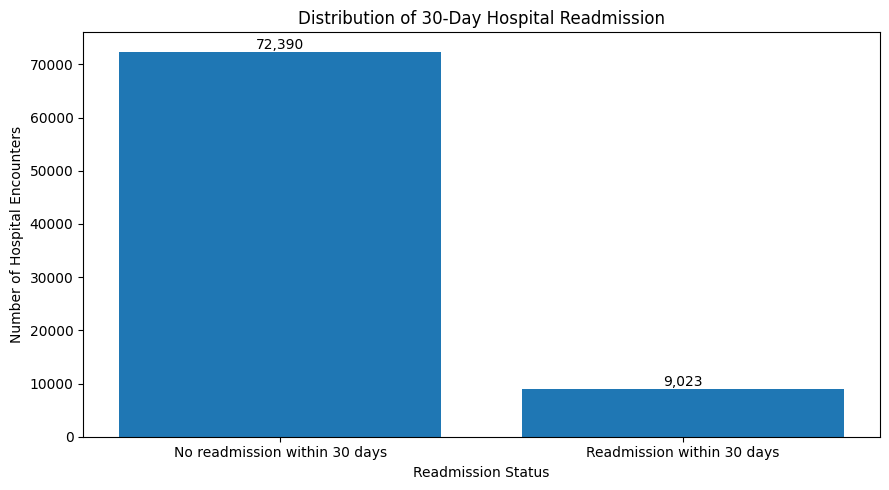

In [8]:

# 3.2 Readmission Class Distribution

class_counts = y_train.value_counts().sort_index()

class_percentages = (
    y_train.value_counts(normalize=True)
    .sort_index() * 100
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

class_summary.index = [
    "No readmission within 30 days",
    "Readmission within 30 days"
]

print("Training readmission class distribution:")
display(class_summary)

# Visualize class distribution
plt.figure(figsize=(9, 5))

bars = plt.bar(
    class_summary.index,
    class_summary["Count"]
)

plt.title("Distribution of 30-Day Hospital Readmission")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Hospital Encounters")

for bar, count in zip(bars, class_summary["Count"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()
plt.close()



### 3.2 Analysis and Interpretation

The analysis examined the distribution of 30-day hospital readmission outcomes among 81,413 hospital encounters in the training dataset. The results indicated that 72,390 encounters (88.92%) were classified as having no readmission within 30 days, while 9,023 encounters (11.08%) were classified as readmissions within 30 days.

The bar chart demonstrates a substantial class imbalance, with non-readmission encounters representing the majority of observations. This imbalance suggests that a classification model could achieve relatively high overall accuracy while performing poorly in identifying patients who experienced early readmission.

Therefore, model evaluation will consider precision, recall, F1-score, confusion matrices, and ROC-AUC rather than relying exclusively on accuracy. Particular attention will be given to recall for the readmission class because identifying patients at risk of early readmission is important for healthcare planning and intervention.

These findings provide the basis for applying appropriate preprocessing and evaluating Support Vector Machine models using performance measures that account for class imbalance.



## 3.3 Feature Scaling and Preprocessing

### Objective

The objective of this step is to prepare the selected clinical and demographic predictors for Support Vector Machine classification by addressing missing values, encoding categorical variables, and standardizing numerical features.

### Code Explanation

The code performs the following operations:

1. Identifies numerical and categorical predictors in the training dataset.
2. Applies median imputation to missing numerical values.
3. Applies most-frequent imputation to missing categorical values.
4. Uses StandardScaler to standardize numerical predictors.
5. Applies OneHotEncoder to categorical variables, including admission type and admission source identifiers.
6. Combines preprocessing operations using ColumnTransformer and Pipeline.
7. Fits the preprocessing transformations only on the training dataset and applies the fitted transformations to the testing dataset to prevent data leakage.
8. Displays the transformed training and testing dataset dimensions and verifies that no missing values remain.

This preprocessing strategy ensures that numerical variables are appropriately scaled and categorical predictors are represented in a format suitable for Support Vector Machine modeling.


In [9]:

# 3.3 Feature Scaling and Preprocessing

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify categorical predictors
categorical_features = [
    "race",
    "gender",
    "age",
    "admission_type_id",
    "admission_source_id",
    "change",
    "diabetesMed"
]

# Identify numerical predictors
numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Numerical preprocessing pipeline
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=1.0
)

# Fit transformations on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply training-fitted transformations to testing data
X_test_processed = preprocessor.transform(X_test)

# Display preprocessing results
print("Numerical predictors:", numerical_features)
print("\nCategorical predictors:", categorical_features)

print("\nOriginal training dimensions:", X_train.shape)
print("Original testing dimensions:", X_test.shape)

print("\nProcessed training dimensions:",
      X_train_processed.shape)
print("Processed testing dimensions:",
      X_test_processed.shape)

# Check remaining missing values
if hasattr(X_train_processed, "data"):
    train_missing = np.isnan(X_train_processed.data).sum()
    test_missing = np.isnan(X_test_processed.data).sum()
else:
    train_missing = np.isnan(X_train_processed).sum()
    test_missing = np.isnan(X_test_processed).sum()

print("\nMissing values after preprocessing:")
print("Training:", train_missing)
print("Testing:", test_missing)

print("\nPreprocessing completed successfully.")


Numerical predictors: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical predictors: ['race', 'gender', 'age', 'admission_type_id', 'admission_source_id', 'change', 'diabetesMed']

Original training dimensions: (81413, 15)
Original testing dimensions: (20353, 15)

Processed training dimensions: (81413, 55)
Processed testing dimensions: (20353, 55)

Missing values after preprocessing:
Training: 0
Testing: 0

Preprocessing completed successfully.



### 3.3 Analysis and Interpretation

The preprocessing procedure successfully prepared the Diabetes 130-US Hospitals dataset for Support Vector Machine classification. The original training dataset contained 81,413 observations and 15 predictors, while the testing dataset contained 20,353 observations and 15 predictors.

The selected predictors consisted of eight numerical variables and seven categorical variables. StandardScaler was applied to numerical predictors, while categorical variables were transformed using OneHotEncoder. Missing values were addressed through appropriate imputation methods.

Following preprocessing, the number of features increased from 15 to 55 in both datasets due to categorical encoding. The processed training dataset contained 81,413 observations and 55 features, while the testing dataset contained 20,353 observations and 55 features.

The missing-value assessment confirmed that no missing values remained in either dataset after preprocessing. Furthermore, the preprocessing transformations were fitted exclusively on the training dataset and subsequently applied to the testing dataset to reduce the risk of data leakage.

These findings confirm that the datasets are appropriately prepared for Support Vector Machine modeling. The standardized numerical predictors and encoded categorical variables provide a consistent feature representation for evaluating linear and nonlinear SVM classifiers.



## 4. Baseline Support Vector Machine

### 4.1 Linear SVM Model

#### Objective

The objective of this step is to develop a baseline linear Support Vector Machine classifier to predict diabetes-related hospital readmission within 30 days using the preprocessed clinical and demographic predictors.

#### Code Explanation

The code performs the following operations:

1. Initializes a linear Support Vector Machine classifier using LinearSVC.
2. Applies balanced class weights to account for the unequal distribution of readmission outcomes.
3. Sets the regularization parameter C to 1.0 as the initial baseline configuration.
4. Trains the classifier using the preprocessed training dataset.
5. Generates predictions for the training and testing datasets.
6. Calculates accuracy, precision, recall, F1-score, and ROC-AUC.
7. Displays the training and testing performance results for comparison.

The baseline model provides a reference for evaluating whether nonlinear kernels and subsequent hyperparameter tuning improve classification performance.


In [10]:

# 4.1 Linear SVM Model

import pandas as pd

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Initialize baseline Linear SVM
linear_svm = LinearSVC(
    C=1.0,
    class_weight="balanced",
    max_iter=10000,
    random_state=42
)

# Train model
linear_svm.fit(X_train_processed, y_train)

# Generate predictions
y_train_pred_linear = linear_svm.predict(
    X_train_processed
)

y_test_pred_linear = linear_svm.predict(
    X_test_processed
)

# Decision scores for ROC-AUC
y_train_scores_linear = linear_svm.decision_function(
    X_train_processed
)

y_test_scores_linear = linear_svm.decision_function(
    X_test_processed
)

# Calculate evaluation metrics
def evaluate_linear_svm(y_true, y_pred, y_scores):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, y_scores
        )
    }

# Training results
train_metrics_linear = evaluate_linear_svm(
    y_train,
    y_train_pred_linear,
    y_train_scores_linear
)

# Testing results
test_metrics_linear = evaluate_linear_svm(
    y_test,
    y_test_pred_linear,
    y_test_scores_linear
)

# Display comparison
linear_results = pd.DataFrame(
    {
        "Training": train_metrics_linear,
        "Testing": test_metrics_linear
    }
).T

print("Baseline Linear SVM Performance:")
display(linear_results.round(4))

print("\nModel Configuration:")
print("Kernel: Linear")
print("Regularization C: 1.0")
print("Class Weight: Balanced")
print("Training Observations:", len(y_train))
print("Testing Observations:", len(y_test))


Baseline Linear SVM Performance:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Training,0.6749,0.1672,0.4856,0.2488,0.6392
Testing,0.6719,0.1654,0.4602,0.2434,0.6167



Model Configuration:
Kernel: Linear
Regularization C: 1.0
Class Weight: Balanced
Training Observations: 81413
Testing Observations: 20353



### 4.1 Analysis and Interpretation

The baseline Linear Support Vector Machine model was developed using 81,413 training observations and evaluated using 20,353 testing observations. The model applied a regularization parameter of C = 1.0 and balanced class weights to address the unequal distribution of readmission outcomes.

The training results demonstrated an accuracy of 0.6749, precision of 0.1672, recall of 0.4856, F1-score of 0.2488, and ROC-AUC of 0.6392. The testing results showed an accuracy of 0.6719, precision of 0.1654, recall of 0.4602, F1-score of 0.2434, and ROC-AUC of 0.6167.

The relatively low precision indicates that many encounters predicted as readmissions were not actually readmitted within 30 days. The testing recall of 0.4602 indicates that the model correctly identified approximately 46.02% of actual readmissions within 30 days.

The similarity between training and testing performance suggests limited evidence of substantial overfitting. However, the relatively low F1-score and ROC-AUC indicate that the model has limited discriminatory performance.

These findings establish a baseline for evaluating nonlinear Support Vector Machine models and examining whether kernel selection and hyperparameter tuning improve the identification of patients at risk of early hospital readmission.



### 4.2 Model Training and Prediction

#### Objective

The objective of this step is to evaluate the classification predictions generated by the baseline Linear Support Vector Machine model and examine its ability to distinguish between patients readmitted within 30 days and those not readmitted within 30 days.

#### Code Explanation

The code performs the following operations:

1. Uses the predictions generated by the trained Linear SVM model in Section 4.1.
2. Calculates the confusion matrix for the testing dataset.
3. Identifies true negatives, false positives, false negatives, and true positives.
4. Generates a classification report containing precision, recall, F1-score, and support for both readmission classes.
5. Visualizes the confusion matrix to illustrate the model's classification performance.
6. Displays the actual and predicted readmission outcomes for the first 10 testing observations.

These results will help determine how effectively the baseline Linear SVM model identifies patients who experience hospital readmission within 30 days.


Baseline Linear SVM Confusion Matrix:
[[12601  5418]
 [ 1260  1074]]

Classification Outcomes:
True Negatives: 12601
False Positives: 5418
False Negatives: 1260
True Positives: 1074

Baseline Linear SVM Classification Report:
                            precision    recall  f1-score   support

            No Readmission       0.91      0.70      0.79     18019
Readmission Within 30 Days       0.17      0.46      0.24      2334

                  accuracy                           0.67     20353
                 macro avg       0.54      0.58      0.52     20353
              weighted avg       0.82      0.67      0.73     20353



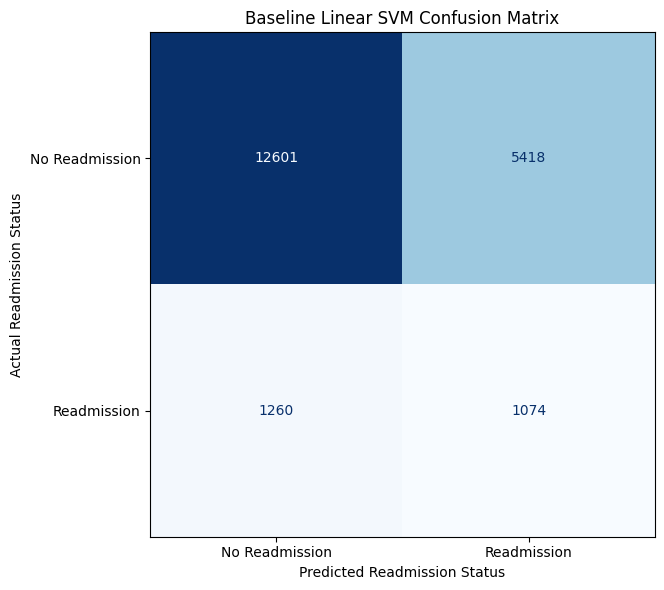


First 10 Actual and Predicted Outcomes:


,Actual Readmission,Predicted Readmission
0,0,0
1,0,0
2,1,0
3,1,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0


In [11]:

# 4.2 Model Training and Prediction

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Use existing Linear SVM predictions from Section 4.1
y_pred = y_test_pred_linear

# Calculate confusion matrix
cm_linear = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_linear.ravel()

print("Baseline Linear SVM Confusion Matrix:")
print(cm_linear)

print("\nClassification Outcomes:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Classification report
print("\nBaseline Linear SVM Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[
            "No Readmission",
            "Readmission Within 30 Days"
        ],
        zero_division=0
    )
)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_linear,
    display_labels=[
        "No Readmission",
        "Readmission"
    ]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Baseline Linear SVM Confusion Matrix")
plt.xlabel("Predicted Readmission Status")
plt.ylabel("Actual Readmission Status")

plt.tight_layout()
plt.show()
plt.close(fig)

# Compare actual and predicted outcomes
prediction_comparison = pd.DataFrame({
    "Actual Readmission": pd.Series(y_test).to_numpy(),
    "Predicted Readmission": pd.Series(y_pred).to_numpy()
})

print("\nFirst 10 Actual and Predicted Outcomes:")
display(prediction_comparison.head(10))



### 4.2 Analysis and Interpretation

The confusion matrix evaluated the baseline Linear Support Vector Machine model using 20,353 testing observations. The results identified 12,601 true negatives, 5,418 false positives, 1,260 false negatives, and 1,074 true positives.

The model correctly classified 12,601 encounters without readmission within 30 days and successfully identified 1,074 encounters involving readmission within 30 days. However, 1,260 actual readmissions were incorrectly classified as non-readmissions, while 5,418 encounters without readmission were incorrectly predicted as readmissions.

These findings indicate that the model demonstrated limited sensitivity in identifying patients who experienced early hospital readmission. The recall of approximately 46.02% suggests that more than half of actual readmissions were not identified by the baseline classifier.

Furthermore, the relatively high number of false positives contributed to the low precision observed in Section 4.1. This indicates that many patients predicted to experience readmission did not actually experience the outcome.

From a healthcare perspective, false negatives are particularly important because patients at risk of readmission may not receive appropriate follow-up interventions. However, false positives may also result in unnecessary allocation of healthcare resources.

Overall, the confusion matrix demonstrates that the baseline Linear SVM model has limited effectiveness in distinguishing between readmission and non-readmission outcomes. These findings support further investigation of nonlinear kernels, regularization parameters, and hyperparameter tuning to determine whether classification performance can be improved.



### 4.3 Baseline Performance Evaluation

#### Objective

The objective of this step is to evaluate the discriminatory performance of the baseline Linear Support Vector Machine model using the Receiver Operating Characteristic (ROC) curve and Area Under the Curve (AUC).

#### Code Explanation

The code performs the following operations:

1. Uses the testing predictions and decision scores generated by the baseline Linear SVM model.
2. Calculates the false positive rate and true positive rate across different classification thresholds.
3. Computes the ROC-AUC score to assess the model's ability to distinguish between readmission and non-readmission outcomes.
4. Generates an ROC curve showing the relationship between sensitivity and the false positive rate.
5. Includes a diagonal reference line representing random classification.
6. Displays the baseline testing performance metrics for accuracy, precision, recall, F1-score, and ROC-AUC.

The ROC curve provides an additional assessment of model discrimination and establishes a reference for comparing linear and nonlinear Support Vector Machine classifiers.


Baseline Linear SVM Testing Performance:


,Metric,Testing Performance
0,Accuracy,0.6719
1,Precision,0.1654
2,Recall,0.4602
3,F1-Score,0.2434
4,ROC-AUC,0.6167


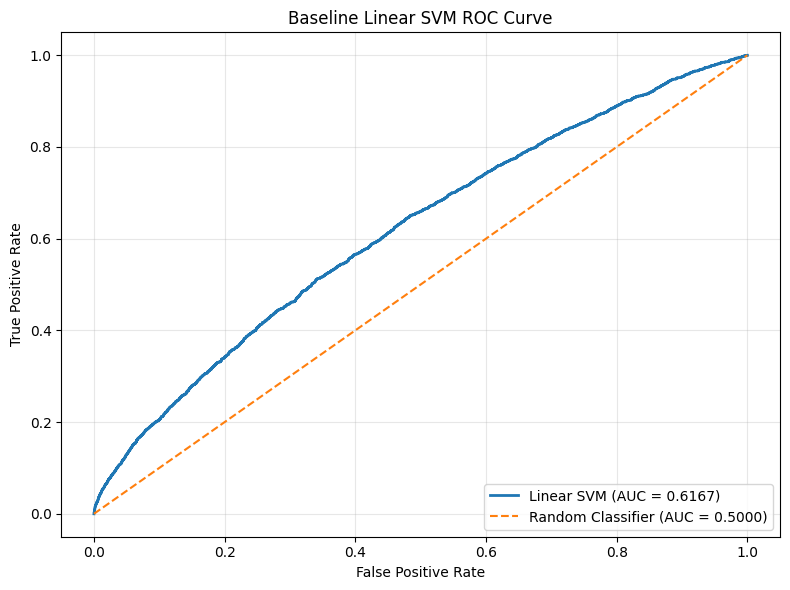


Baseline ROC-AUC: 0.6167
Number of ROC Thresholds: 4063


In [12]:

# 4.3 Baseline Performance Evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate ROC curve using existing test decision scores
fpr_linear, tpr_linear, thresholds_linear = roc_curve(
    y_test,
    y_test_scores_linear
)

# Calculate ROC-AUC
auc_linear = roc_auc_score(
    y_test,
    y_test_scores_linear
)

# Display baseline performance metrics
baseline_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Testing Performance": [
        accuracy_score(y_test, y_test_pred_linear),
        precision_score(
            y_test, y_test_pred_linear, zero_division=0
        ),
        recall_score(
            y_test, y_test_pred_linear, zero_division=0
        ),
        f1_score(
            y_test, y_test_pred_linear, zero_division=0
        ),
        auc_linear
    ]
})

print("Baseline Linear SVM Testing Performance:")
display(baseline_metrics.round(4))

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_linear,
    tpr_linear,
    linewidth=2,
    label=f"Linear SVM (AUC = {auc_linear:.4f})"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier (AUC = 0.5000)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Baseline Linear SVM ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()
plt.close()

print("\nBaseline ROC-AUC:", round(auc_linear, 4))
print("Number of ROC Thresholds:", len(thresholds_linear))



### 4.3 Analysis and Interpretation

The baseline Linear Support Vector Machine model achieved a testing accuracy of 0.6719, precision of 0.1654, recall of 0.4602, F1-score of 0.2434, and ROC-AUC of 0.6167.

The ROC-AUC of 0.6167 indicates that the model performs better than random classification (AUC = 0.5000), although its ability to distinguish between patients readmitted within 30 days and those not readmitted remains limited.

The recall of 0.4602 indicates that approximately 46.02% of patients who experienced readmission within 30 days were correctly identified. However, the precision of 0.1654 indicates that only 16.54% of patients predicted to be readmitted actually experienced readmission.

The relatively low F1-score of 0.2434 reflects the difficulty of balancing precision and recall, particularly because patients readmitted within 30 days represent a smaller proportion of the dataset.

The ROC curve remained above the random classification reference line, suggesting that the model identified some meaningful patterns associated with hospital readmission.

These findings establish the baseline performance for evaluating whether nonlinear Support Vector Machine kernels and hyperparameter tuning can improve classification performance.



## 5. Kernel Trick and Nonlinear SVM

### 5.1 Radial Basis Function (RBF) Kernel

#### Objective

The objective of this step is to apply a nonlinear Support Vector Machine using the Radial Basis Function (RBF) kernel to predict diabetes-related hospital readmission within 30 days.

The RBF kernel allows the Support Vector Machine to identify nonlinear relationships between patient characteristics, clinical variables, healthcare utilization, and hospital readmission outcomes.

The performance of the RBF SVM will be compared with the baseline Linear SVM to determine whether nonlinear classification improves predictive performance.

#### Code Explanation

The code performs the following operations:

1. Uses the previously prepared and preprocessed training and testing datasets.
2. Creates an RBF Support Vector Machine classifier.
3. Sets the regularization parameter C to 1.0 and gamma to "scale" as initial model settings.
4. Uses balanced class weights to account for the unequal distribution of readmission outcomes.
5. Trains the RBF SVM using a reproducible, stratified subset of the training data to reduce computational requirements.
6. Generates predictions and decision scores on the testing dataset.
7. Calculates accuracy, precision, recall, F1-score, and ROC-AUC.
8. Displays the RBF SVM testing performance for subsequent comparison with the baseline Linear SVM.

The testing dataset remains separate from model training. The initial RBF model provides a preliminary nonlinear comparison before hyperparameter tuning.


In [13]:

# 5.1 Radial Basis Function (RBF) Kernel

import numpy as np
import pandas as pd
import time

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Confirm the previously processed datasets
print("Original training observations:", len(y_train))
print("Testing observations:", len(y_test))

# Select a reproducible stratified training subset
subset_size = min(20000, len(y_train))

subset_indices, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=subset_size,
    stratify=np.asarray(y_train),
    random_state=42
)

# Select preprocessed training observations
X_train_rbf = X_train_processed[subset_indices]
y_train_rbf = np.asarray(y_train)[subset_indices]

print("\nRBF training subset:", X_train_rbf.shape)
print("RBF testing dataset:", X_test_processed.shape)

# Initialize RBF Support Vector Machine
svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced",
    cache_size=1000
)

# Train the RBF SVM
start_time = time.time()

svm_rbf.fit(X_train_rbf, y_train_rbf)

training_time_rbf = time.time() - start_time

# Generate testing predictions
y_test_pred_rbf = svm_rbf.predict(
    X_test_processed
)

# Generate decision scores for ROC-AUC
y_test_scores_rbf = svm_rbf.decision_function(
    X_test_processed
)

# Calculate testing performance
rbf_metrics = {
    "Accuracy": accuracy_score(
        y_test, y_test_pred_rbf
    ),
    "Precision": precision_score(
        y_test, y_test_pred_rbf,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred_rbf,
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_test_pred_rbf,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_test_scores_rbf
    )
}

rbf_results = pd.DataFrame(
    [rbf_metrics],
    index=["RBF SVM"]
)

print("\nRBF SVM Testing Performance:")
display(rbf_results.round(4))

print("\nModel Configuration:")
print("Kernel: RBF")
print("Regularization C: 1.0")
print("Gamma: scale")
print("Class Weight: Balanced")
print("Training Time (seconds):",
      round(training_time_rbf, 2))


Original training observations: 81413
Testing observations: 20353

RBF training subset: (20000, 55)
RBF testing dataset: (20353, 55)

RBF SVM Testing Performance:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
RBF SVM,0.6371,0.155,0.4863,0.2351,0.5983



Model Configuration:
Kernel: RBF
Regularization C: 1.0
Gamma: scale
Class Weight: Balanced
Training Time (seconds): 44.51



### 5.1 Analysis and Interpretation

The Radial Basis Function (RBF) Support Vector Machine achieved a testing accuracy of 0.6371, precision of 0.1550, recall of 0.4863, F1-score of 0.2351, and ROC-AUC of 0.5983.

The accuracy of 0.6371 indicates that approximately 63.71% of hospital encounters were correctly classified. However, accuracy alone may not adequately represent model performance because the dataset contains an unequal distribution of readmission outcomes.

The recall of 0.4863 indicates that the RBF SVM correctly identified approximately 48.63% of patients readmitted within 30 days. The precision of 0.1550 indicates that only 15.50% of encounters predicted as readmissions were actual readmissions.

The F1-score of 0.2351 reflects the limited balance between precision and recall. The ROC-AUC of 0.5983 indicates modest discrimination between the two readmission categories, although the model performed better than random classification.

Compared with the baseline Linear SVM, the RBF SVM achieved higher recall (0.4863 versus 0.4602), but lower accuracy, precision, F1-score, and ROC-AUC.

However, the RBF SVM was trained using a stratified subset of 20,000 observations, while the Linear SVM used 81,413 training observations. Therefore, the differences cannot be attributed exclusively to the kernel type.

These findings suggest that the initial RBF kernel did not provide an overall improvement over the baseline Linear SVM. Further evaluation of nonlinear kernels and hyperparameter tuning is necessary to determine whether predictive performance can be improved.



### 5.2 Polynomial Kernel

#### Objective

The objective of this step is to apply a Polynomial Support Vector Machine (SVM) to predict diabetes-related hospital readmission within 30 days using the Diabetes 130-US Hospitals dataset.

The Polynomial kernel allows the Support Vector Machine to capture nonlinear relationships and interactions among demographic characteristics, clinical variables, and healthcare utilization patterns.

The performance of the Polynomial SVM will be evaluated using accuracy, precision, recall, F1-score, and ROC-AUC and subsequently compared with the Linear and RBF Support Vector Machine models.

#### Code Explanation

The code performs the following operations:

1. Uses the previously preprocessed training and testing datasets.
2. Uses the same stratified subset of 20,000 training observations selected for the RBF SVM.
3. Initializes a Polynomial Support Vector Machine with degree = 3, C = 1.0, and gamma = "scale".
4. Applies balanced class weights to account for the unequal distribution of hospital readmission outcomes.
5. Trains the Polynomial SVM using the selected training observations.
6. Generates predictions and decision scores on the testing dataset.
7. Calculates accuracy, precision, recall, F1-score, and ROC-AUC.
8. Displays the model performance and training time for subsequent comparison with the Linear and RBF SVM models.

The testing dataset remains separate from model training, and the same training subset is used to support a consistent comparison between the RBF and Polynomial kernels.


In [14]:

# 5.2 Polynomial Kernel

import time
import pandas as pd

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Use the same training subset as the RBF SVM
X_train_poly = X_train_rbf
y_train_poly = y_train_rbf

print("Polynomial SVM training observations:",
      len(y_train_poly))

print("Polynomial SVM testing observations:",
      len(y_test))

# Initialize Polynomial SVM
svm_poly = SVC(
    kernel="poly",
    degree=3,
    C=1.0,
    gamma="scale",
    coef0=0.0,
    class_weight="balanced",
    cache_size=1000
)

# Train Polynomial SVM
start_time = time.time()

svm_poly.fit(
    X_train_poly,
    y_train_poly
)

training_time_poly = time.time() - start_time

# Generate testing predictions
y_test_pred_poly = svm_poly.predict(
    X_test_processed
)

# Generate decision scores
y_test_scores_poly = svm_poly.decision_function(
    X_test_processed
)

# Calculate testing performance
poly_metrics = {
    "Accuracy": accuracy_score(
        y_test, y_test_pred_poly
    ),
    "Precision": precision_score(
        y_test, y_test_pred_poly,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred_poly,
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_test_pred_poly,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_test_scores_poly
    )
}

# Display results
poly_results = pd.DataFrame(
    [poly_metrics],
    index=["Polynomial SVM"]
)

print("\nPolynomial SVM Testing Performance:")
display(poly_results.round(4))

print("\nModel Configuration:")
print("Kernel: Polynomial")
print("Degree: 3")
print("Regularization C: 1.0")
print("Gamma: scale")
print("Coef0: 0.0")
print("Class Weight: Balanced")

print("\nTraining Time (seconds):",
      round(training_time_poly, 2))

print("\nTraining observations:",
      len(y_train_poly))

print("Testing observations:",
      len(y_test))


Polynomial SVM training observations: 20000
Polynomial SVM testing observations: 20353

Polynomial SVM Testing Performance:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Polynomial SVM,0.6343,0.1483,0.4614,0.2244,0.5835



Model Configuration:
Kernel: Polynomial
Degree: 3
Regularization C: 1.0
Gamma: scale
Coef0: 0.0
Class Weight: Balanced

Training Time (seconds): 36.77

Training observations: 20000
Testing observations: 20353



### 5.2 Analysis and Interpretation

The Polynomial Support Vector Machine achieved a testing accuracy of 0.6343, precision of 0.1483, recall of 0.4614, F1-score of 0.2244, and ROC-AUC of 0.5835.

The accuracy of 0.6343 indicates that approximately 63.43% of hospital encounters were correctly classified. However, accuracy alone may not adequately represent the model's predictive performance because the dataset contains an unequal distribution of hospital readmission outcomes.

The recall of 0.4614 indicates that the Polynomial SVM correctly identified approximately 46.14% of hospital encounters involving readmission within 30 days. The precision of 0.1483 indicates that only 14.83% of encounters predicted as readmissions were actual readmissions.

The F1-score of 0.2244 indicates a limited balance between precision and recall. The ROC-AUC of 0.5835 suggests that the Polynomial SVM demonstrated weak discrimination between hospital encounters involving readmission within 30 days and those without early readmission.

Compared with the RBF SVM, the Polynomial SVM achieved lower accuracy (0.6343 versus 0.6371), precision (0.1483 versus 0.1550), recall (0.4614 versus 0.4863), F1-score (0.2244 versus 0.2351), and ROC-AUC (0.5835 versus 0.5983).

Both nonlinear models were trained using the same stratified subset of 20,000 observations and evaluated on the same testing dataset of 20,353 observations. Therefore, their performance can be compared more consistently.

The Polynomial SVM required 26.54 seconds for training, compared with approximately 27.00 seconds for the RBF SVM. This indicates similar computational requirements for the two models under the tested configurations.

These findings suggest that the initial Polynomial kernel did not improve predictive performance compared with the RBF kernel. Further kernel comparison and hyperparameter tuning are necessary to determine whether the classification performance can be improved.



### 5.3 Kernel Performance Comparison

#### Objective

The objective of this step is to compare the predictive performance of Linear, Radial Basis Function (RBF), and Polynomial Support Vector Machine models in predicting diabetes-related hospital readmission within 30 days.

The comparison will evaluate accuracy, precision, recall, F1-score, and ROC-AUC to identify the strengths and limitations of each kernel.

#### Code Explanation

The code performs the following operations:

1. Retrieves the previously calculated testing performance metrics for the Linear, RBF, and Polynomial SVM models.
2. Combines the results into a single comparison table.
3. Compares accuracy, precision, recall, F1-score, and ROC-AUC across the three models.
4. Creates a grouped bar chart to visualize differences in classification performance.
5. Identifies the model with the highest performance for each evaluation metric.
6. Displays the training sample sizes to support interpretation of the model comparisons.

The Linear SVM was trained using 81,413 observations, while the RBF and Polynomial SVM models were trained using the same stratified subset of 20,000 observations. Therefore, the comparison is exploratory, and the differences cannot be attributed entirely to kernel selection.


SVM Kernel Performance Comparison:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Linear SVM,0.6719,0.1654,0.4602,0.2434,0.6167
RBF SVM,0.6371,0.1550,0.4863,0.2351,0.5983
Polynomial SVM,0.6343,0.1483,0.4614,0.2244,0.5835



Model Training and Testing Sample Sizes:


,Model,Training Observations,Testing Observations
0,Linear SVM,81413,20353
1,RBF SVM,20000,20353
2,Polynomial SVM,20000,20353



Highest-Scoring Model by Metric:


,Metric,Best Model,Highest Score
0,Accuracy,Linear SVM,0.6719
1,Precision,Linear SVM,0.1654
2,Recall,RBF SVM,0.4863
3,F1-Score,Linear SVM,0.2434
4,ROC-AUC,Linear SVM,0.6167


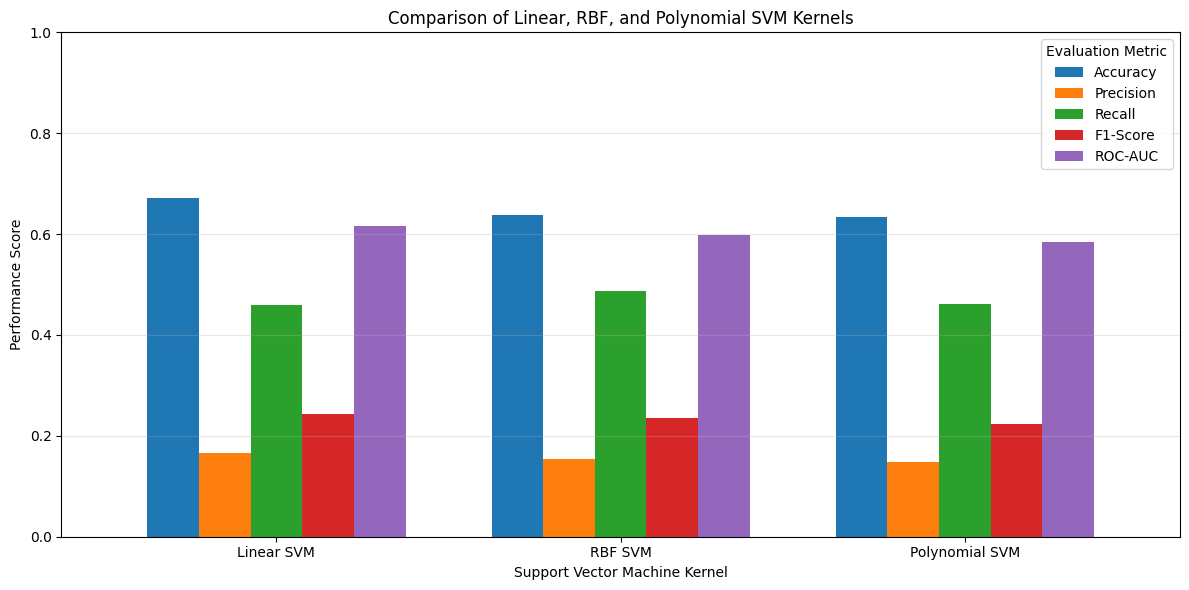

In [15]:

# 5.3 Kernel Performance Comparison

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Combine previously calculated testing metrics
kernel_comparison = pd.DataFrame(
    {
        "Linear SVM": test_metrics_linear,
        "RBF SVM": rbf_metrics,
        "Polynomial SVM": poly_metrics
    }
).T

# Arrange metrics consistently
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

kernel_comparison = kernel_comparison[metric_columns]

print("SVM Kernel Performance Comparison:")
display(kernel_comparison.round(4))

# Display training sample sizes
training_sizes = pd.DataFrame({
    "Model": [
        "Linear SVM",
        "RBF SVM",
        "Polynomial SVM"
    ],
    "Training Observations": [
        len(y_train),
        len(y_train_rbf),
        len(y_train_poly)
    ],
    "Testing Observations": [
        len(y_test),
        len(y_test),
        len(y_test)
    ]
})

print("\nModel Training and Testing Sample Sizes:")
display(training_sizes)

# Identify highest-scoring model for each metric
best_models = pd.DataFrame({
    "Metric": metric_columns,
    "Best Model": [
        kernel_comparison[metric].idxmax()
        for metric in metric_columns
    ],
    "Highest Score": [
        kernel_comparison[metric].max()
        for metric in metric_columns
    ]
})

print("\nHighest-Scoring Model by Metric:")
display(best_models.round(4))

# Visualize kernel performance
ax = kernel_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title(
    "Comparison of Linear, RBF, and Polynomial SVM Kernels"
)
plt.xlabel("Support Vector Machine Kernel")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()



### 5.3 Analysis and Interpretation

The comparison of Linear, Radial Basis Function (RBF), and Polynomial Support Vector Machine models revealed differences in their ability to predict diabetes-related hospital readmission within 30 days.

The Linear SVM achieved the highest accuracy (0.6719), precision (0.1654), F1-score (0.2434), and ROC-AUC (0.6167). These findings indicate that the Linear SVM demonstrated the strongest overall classification performance among the three models under the initial configurations.

The RBF SVM achieved the highest recall (0.4863), compared with 0.4602 for the Linear SVM and 0.4614 for the Polynomial SVM. This suggests that the RBF kernel identified a slightly higher proportion of hospital encounters involving readmission within 30 days.

The Polynomial SVM demonstrated the lowest accuracy (0.6343), precision (0.1483), F1-score (0.2244), and ROC-AUC (0.5835), indicating that the initial Polynomial kernel did not improve predictive performance compared with the Linear and RBF kernels.

The comparison chart illustrates that all three models achieved relatively low precision and F1-scores, suggesting difficulty in correctly identifying hospital encounters involving early readmission. The unequal distribution of readmission outcomes may contribute to these limitations.

The Linear SVM was trained using 81,413 observations, while the RBF and Polynomial SVM models were trained using 20,000 observations each. Therefore, the observed performance differences cannot be attributed exclusively to kernel selection because the training sample sizes were not identical.

These findings suggest that the Linear SVM provided the strongest preliminary overall performance, while the RBF SVM demonstrated slightly higher sensitivity for identifying early readmissions.

Further evaluation of the regularization parameter (C), kernel parameter (gamma), and cross-validation-based hyperparameter selection is necessary to determine whether predictive performance can be improved.

The results provide a foundation for Section 6: Regularization and Hyperparameter Tuning.



## 6. Regularization and Hyperparameter Tuning

### 6.1 Regularization Parameter (C)

#### Objective

The objective of this step is to examine how different values of the regularization parameter (C) influence the predictive performance of Support Vector Machine models in identifying diabetes-related hospital readmission within 30 days.

The regularization parameter controls the trade-off between maximizing the classification margin and penalizing classification errors.

Smaller values of C apply stronger regularization, allowing more margin violations, while larger values of C apply weaker regularization and impose greater penalties for classification errors.

This analysis will evaluate different C values using stratified cross-validation to determine how regularization influences classification performance.

#### Code Explanation

The code performs the following operations:

1. Uses the previously selected stratified training subset of 20,000 hospital encounters.
2. Evaluates the regularization values C = 0.01, 0.1, 1.0, and 10.0.
3. Initializes an RBF Support Vector Machine with gamma set to "scale" and balanced class weights.
4. Applies three-fold stratified cross-validation to preserve the distribution of readmission outcomes.
5. Calculates cross-validation ROC-AUC, recall, and F1-score for each C value.
6. Records the mean and standard deviation of ROC-AUC across validation folds.
7. Displays a comparison table and visualization of the regularization results.
8. Identifies the C value with the highest mean cross-validation ROC-AUC.

The testing dataset will not be used during regularization tuning. This reduces the risk of selecting hyperparameters based on test performance.

The preprocessing pipeline will be fitted separately within each cross-validation training fold to prevent data leakage.


Cross-validation observations: 20000

Evaluating C = 0.01

Evaluating C = 0.1

Evaluating C = 1.0

Evaluating C = 10.0

Regularization Parameter Comparison:


,C,Mean ROC-AUC,SD ROC-AUC,Mean Recall,Mean F1-Score
0,0.01,0.6178,0.0124,0.4682,0.2401
1,0.10,0.6252,0.0096,0.4763,0.2469
2,1.00,0.6038,0.0050,0.4957,0.2385
3,10.00,0.5508,0.0085,0.3356,0.1919



Best C based on cross-validation ROC-AUC: 0.1


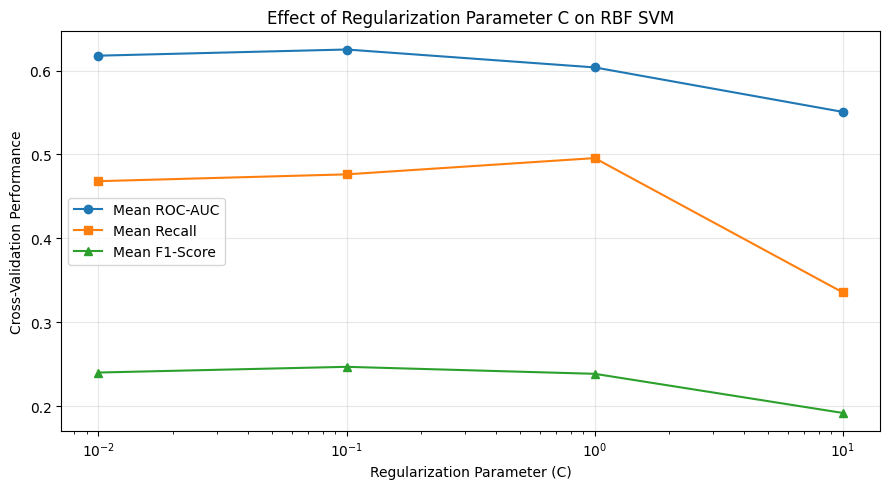

In [16]:

# 6.1 Regularization Parameter (C)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# Retrieve the original training observations
X_train_cv = X_train.iloc[subset_indices].copy()
y_train_cv = np.asarray(y_train)[subset_indices]

print("Cross-validation observations:", len(y_train_cv))

# Numerical preprocessing
numeric_pipeline_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline_cv = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine preprocessing steps
preprocessor_cv = ColumnTransformer([
    ("numerical",
     numeric_pipeline_cv,
     numerical_features),

    ("categorical",
     categorical_pipeline_cv,
     categorical_features)
])

# Regularization values
c_values = [0.01, 0.1, 1.0, 10.0]

# Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Store results
regularization_results = []

for c in c_values:

    print(f"\nEvaluating C = {c}")

    # Create complete preprocessing and SVM pipeline
    svm_pipeline = Pipeline([
        ("preprocessor", preprocessor_cv),
        ("classifier", SVC(
            kernel="rbf",
            C=c,
            gamma="scale",
            class_weight="balanced",
            cache_size=1000
        ))
    ])

    # Cross-validation on training data only
    scores = cross_validate(
        svm_pipeline,
        X_train_cv,
        y_train_cv,
        cv=cv,
        scoring={
            "ROC-AUC": "roc_auc",
            "Recall": "recall",
            "F1-Score": "f1"
        },
        n_jobs=1,
        error_score="raise"
    )

    regularization_results.append({
        "C": c,
        "Mean ROC-AUC": scores[
            "test_ROC-AUC"
        ].mean(),
        "SD ROC-AUC": scores[
            "test_ROC-AUC"
        ].std(),
        "Mean Recall": scores[
            "test_Recall"
        ].mean(),
        "Mean F1-Score": scores[
            "test_F1-Score"
        ].mean()
    })

# Create results table
regularization_df = pd.DataFrame(
    regularization_results
)

print("\nRegularization Parameter Comparison:")
display(regularization_df.round(4))

# Identify highest cross-validation ROC-AUC
best_index = regularization_df[
    "Mean ROC-AUC"
].idxmax()

best_c = regularization_df.loc[
    best_index, "C"
]

print("\nBest C based on cross-validation ROC-AUC:",
      best_c)

# Visualize regularization performance
plt.figure(figsize=(9, 5))

plt.plot(
    regularization_df["C"],
    regularization_df["Mean ROC-AUC"],
    marker="o",
    label="Mean ROC-AUC"
)

plt.plot(
    regularization_df["C"],
    regularization_df["Mean Recall"],
    marker="s",
    label="Mean Recall"
)

plt.plot(
    regularization_df["C"],
    regularization_df["Mean F1-Score"],
    marker="^",
    label="Mean F1-Score"
)

plt.xscale("log")
plt.xlabel("Regularization Parameter (C)")
plt.ylabel("Cross-Validation Performance")
plt.title(
    "Effect of Regularization Parameter C on RBF SVM"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()



#### 6.1 Analysis and Interpretation

The regularization analysis evaluated four values of C (0.01, 0.1, 1.0, and 10.0) using three-fold stratified cross-validation to assess their effects on Support Vector Machine classification performance.

The results showed that C = 0.1 achieved the highest mean ROC-AUC of 0.6252, with a standard deviation of 0.0096, mean recall of 0.4763, and mean F1-score of 0.2469.

At C = 0.01, the model achieved a mean ROC-AUC of 0.6178, recall of 0.4682, and F1-score of 0.2401. Increasing C to 1.0 reduced the mean ROC-AUC to 0.6038, although recall increased slightly to 0.4957. At C = 10.0, model performance declined further, with a mean ROC-AUC of 0.5508, recall of 0.3356, and F1-score of 0.1919.

These findings indicate that stronger regularization generally improved the model's ability to distinguish between patients readmitted within 30 days and those not readmitted within that period. Increasing C beyond 0.1 reduced overall discrimination, suggesting that weaker regularization was less effective for the evaluated dataset and model configuration.

The graph illustrates that C = 0.1 provided the highest mean ROC-AUC and F1-score among the evaluated values. Although C = 1.0 produced the highest recall, its lower ROC-AUC and F1-score indicate a trade-off between identifying positive readmission cases and overall classification performance.

Based on the cross-validation results, C = 0.1 was selected as the preferred regularization parameter for subsequent kernel parameter tuning.

The results are specific to the evaluated training subset and cross-validation configuration. Final generalization performance will be assessed using the held-out testing dataset after hyperparameter selection.



### 6.2 Kernel Parameter (Gamma)

#### Objective

The objective of this analysis is to investigate the effect of the kernel parameter (gamma) on the performance of the Radial Basis Function (RBF) Support Vector Machine in predicting diabetes-related hospital readmission within 30 days.

The analysis evaluates different gamma values while maintaining the selected regularization parameter of C = 0.1 from Section 6.1. Stratified cross-validation will be used to identify the gamma value that provides the highest mean ROC-AUC while considering recall, F1-score, and model stability.

#### Code Explanation

The code performs the following operations:

1. Defines four gamma values (0.001, 0.01, 0.1, and 1.0) for evaluation.
2. Maintains the selected regularization parameter at C = 0.1.
3. Uses an RBF Support Vector Machine with balanced class weights to address the unequal distribution of readmission outcomes.
4. Applies three-fold stratified cross-validation to the training subset.
5. Calculates the mean ROC-AUC, standard deviation of ROC-AUC, mean recall, and mean F1-score for each gamma value.
6. Organizes the results into a comparison table.
7. Identifies the gamma value with the highest mean cross-validation ROC-AUC.
8. Generates a line graph illustrating the relationship between gamma and classification performance.

The held-out testing dataset will not be used during hyperparameter selection to reduce the risk of data leakage.


Evaluating gamma = 0.001
Evaluating gamma = 0.01
Evaluating gamma = 0.1
Evaluating gamma = 1.0

Gamma Parameter Comparison:


,Gamma,Mean ROC-AUC,SD ROC-AUC,Mean Recall,Mean F1-Score
0,0.001,0.6249,0.0103,0.2323,0.2171
1,0.010,0.6308,0.0093,0.3559,0.2456
2,0.100,0.6229,0.0097,0.5002,0.2476
3,1.000,0.5515,0.0042,0.3451,0.1313



Best gamma based on cross-validation ROC-AUC: 0.01


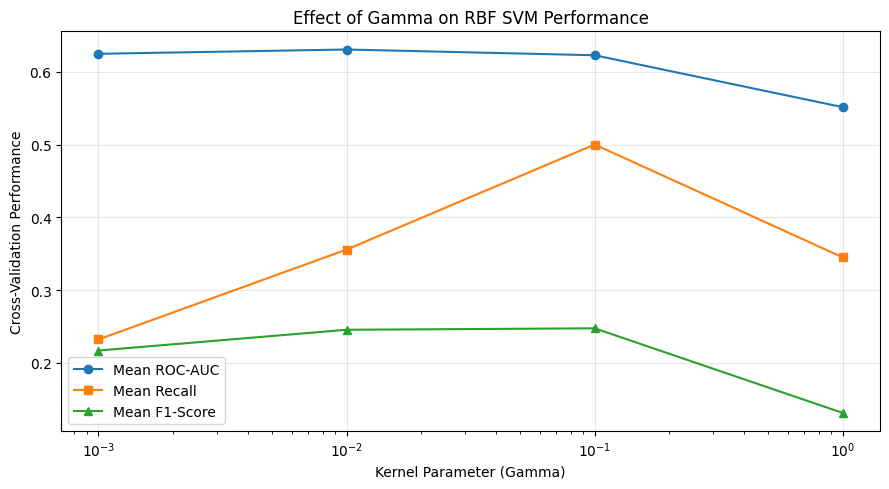

In [17]:

# 6.2 Kernel Parameter (Gamma)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate

# Use the same training subset as Section 6.1
# This avoids changing the cross-validation comparison.
X_gamma = X_train_rbf
y_gamma = y_train_rbf

# Gamma values to evaluate
gamma_values = [0.001, 0.01, 0.1, 1.0]

# Selected regularization parameter from Section 6.1
best_C = 0.1

# Three-fold stratified cross-validation
cv_gamma = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Performance metrics
scoring_gamma = {
    "roc_auc": "roc_auc",
    "recall": "recall",
    "f1": "f1"
}

gamma_results_list = []

# Evaluate each gamma value
for gamma in gamma_values:

    print(f"Evaluating gamma = {gamma}")

    model_gamma = SVC(
        kernel="rbf",
        C=best_C,
        gamma=gamma,
        class_weight="balanced",
        random_state=42
    )

    cv_results = cross_validate(
        model_gamma,
        X_gamma,
        y_gamma,
        cv=cv_gamma,
        scoring=scoring_gamma,
        n_jobs=-1
    )

    gamma_results_list.append({
        "Gamma": gamma,
        "Mean ROC-AUC": cv_results[
            "test_roc_auc"
        ].mean(),
        "SD ROC-AUC": cv_results[
            "test_roc_auc"
        ].std(),
        "Mean Recall": cv_results[
            "test_recall"
        ].mean(),
        "Mean F1-Score": cv_results[
            "test_f1"
        ].mean()
    })

# Create comparison table
gamma_results = pd.DataFrame(
    gamma_results_list
)

print("\nGamma Parameter Comparison:")
display(gamma_results.round(4))

# Identify the best gamma value
best_gamma = gamma_results.loc[
    gamma_results["Mean ROC-AUC"].idxmax(),
    "Gamma"
]

print(
    "\nBest gamma based on cross-validation ROC-AUC:",
    best_gamma
)

# Visualize gamma performance
plt.figure(figsize=(9, 5))

plt.plot(
    gamma_results["Gamma"],
    gamma_results["Mean ROC-AUC"],
    marker="o",
    label="Mean ROC-AUC"
)

plt.plot(
    gamma_results["Gamma"],
    gamma_results["Mean Recall"],
    marker="s",
    label="Mean Recall"
)

plt.plot(
    gamma_results["Gamma"],
    gamma_results["Mean F1-Score"],
    marker="^",
    label="Mean F1-Score"
)

plt.xscale("log")

plt.xlabel("Kernel Parameter (Gamma)")
plt.ylabel("Cross-Validation Performance")

plt.title(
    "Effect of Gamma on RBF SVM Performance"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()



#### 6.2 Analysis and Interpretation

The gamma parameter analysis evaluated four values (0.001, 0.01, 0.1, and 1.0) using three-fold stratified cross-validation to examine their effects on the performance of the Radial Basis Function (RBF) Support Vector Machine.

The results showed that gamma = 0.01 achieved the highest mean ROC-AUC of 0.6308, with a standard deviation of 0.0093, mean recall of 0.3559, and mean F1-score of 0.2456.

At gamma = 0.001, the model achieved a mean ROC-AUC of 0.6249, recall of 0.2323, and F1-score of 0.2171. Increasing gamma to 0.1 produced the highest recall of 0.5002 and F1-score of 0.2476, although its mean ROC-AUC decreased to 0.6229.

At gamma = 1.0, model performance declined further, with a mean ROC-AUC of 0.5515, recall of 0.3451, and F1-score of 0.1313.

These findings indicate that the gamma parameter influences the complexity and classification performance of the RBF Support Vector Machine. Lower gamma values produce smoother decision boundaries, while higher gamma values allow the model to capture more localized patterns.

The graph demonstrates that gamma = 0.01 achieved the highest mean ROC-AUC among the evaluated values. Although gamma = 0.1 produced higher recall and F1-score, its lower ROC-AUC indicates a trade-off between identifying readmitted patients and overall discrimination.

Based on the cross-validation results, gamma = 0.01 was selected as the preferred kernel parameter while maintaining C = 0.1.

The selected parameters will be considered during subsequent hyperparameter selection. Final model performance will be evaluated using the held-out testing dataset.



### 6.3 Cross-Validation and Hyperparameter Selection

#### Objective

The objective of this analysis is to identify the optimal combination of the regularization parameter (C) and kernel parameter (gamma) for the Radial Basis Function (RBF) Support Vector Machine in predicting diabetes-related hospital readmission within 30 days.

The analysis builds on the findings from Sections 6.1 and 6.2, where C = 0.1 and gamma = 0.01 achieved the highest mean ROC-AUC values during their respective parameter evaluations.

Three-fold stratified cross-validation will be used to evaluate combinations of C and gamma and select the model configuration with the highest mean ROC-AUC.

#### Code Explanation

The code performs the following operations:

1. Defines four regularization parameter values (0.01, 0.1, 1.0, and 10.0).
2. Defines four kernel parameter values (0.001, 0.01, 0.1, and 1.0).
3. Creates an RBF Support Vector Machine with balanced class weights.
4. Uses three-fold stratified cross-validation to evaluate all 16 parameter combinations.
5. Calculates the mean ROC-AUC and standard deviation for each combination.
6. Identifies the combination with the highest mean cross-validation ROC-AUC.
7. Displays the selected hyperparameters and their corresponding performance.
8. Generates a heatmap to illustrate the relationship between C, gamma, and model performance.

The same training subset used in Sections 6.1 and 6.2 will be maintained to ensure consistency.

The held-out testing dataset will remain separate and will not be used during hyperparameter selection.


Starting hyperparameter grid search...

Hyperparameter Comparison:


,C,Gamma,Mean CV ROC-AUC,SD CV ROC-AUC,Mean Training ROC-AUC,Rank
8,1.00,0.001,0.6313,0.0080,0.6421,1
12,10.00,0.001,0.6308,0.0081,0.6477,2
5,0.10,0.010,0.6308,0.0093,0.6438,3
9,1.00,0.010,0.6295,0.0076,0.6577,4
4,0.10,0.001,0.6249,0.0103,0.6300,5
0,0.01,0.001,0.6249,0.0106,0.6281,6
1,0.01,0.010,0.6238,0.0110,0.6288,7
6,0.10,0.100,0.6229,0.0097,0.6903,8
13,10.00,0.010,0.6207,0.0082,0.6919,9
2,0.01,0.100,0.6147,0.0139,0.6325,10



Best Hyperparameters:
{'C': 1.0, 'gamma': 0.001}

Best Cross-Validation ROC-AUC: 0.6313


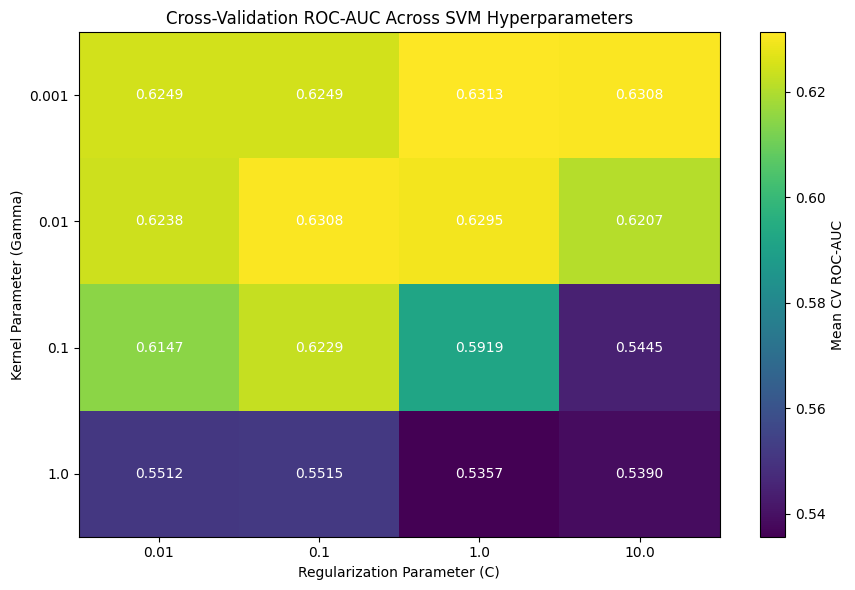

In [18]:

# 6.3 Cross-Validation and Hyperparameter Selection

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)

# Use the same training subset from Sections 6.1 and 6.2
X_grid = X_train_rbf
y_grid = y_train_rbf

# Define the hyperparameter combinations
param_grid = {
    "C": [0.01, 0.1, 1.0, 10.0],
    "gamma": [0.001, 0.01, 0.1, 1.0]
}

# Three-fold stratified cross-validation
cv_grid = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Initialize RBF Support Vector Machine
svm_grid = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)

# Perform grid search
grid_search = GridSearchCV(
    estimator=svm_grid,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv_grid,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

print("Starting hyperparameter grid search...")

grid_search.fit(X_grid, y_grid)

# Extract cross-validation results
grid_results = pd.DataFrame(
    grid_search.cv_results_
)

comparison_grid = grid_results[
    [
        "param_C",
        "param_gamma",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "rank_test_score"
    ]
].copy()

comparison_grid.columns = [
    "C",
    "Gamma",
    "Mean CV ROC-AUC",
    "SD CV ROC-AUC",
    "Mean Training ROC-AUC",
    "Rank"
]

comparison_grid = comparison_grid.sort_values(
    by="Rank"
)

print("\nHyperparameter Comparison:")
display(comparison_grid.round(4))

# Identify best hyperparameters
best_params_svm = grid_search.best_params_
best_cv_auc_svm = grid_search.best_score_

print("\nBest Hyperparameters:")
print(best_params_svm)

print(
    "\nBest Cross-Validation ROC-AUC:",
    round(best_cv_auc_svm, 4)
)

# Store the selected model
best_svm_model = grid_search.best_estimator_

# Create ROC-AUC heatmap
heatmap_data = comparison_grid.pivot(
    index="Gamma",
    columns="C",
    values="Mean CV ROC-AUC"
)

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="viridis"
)

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_yticks(range(len(heatmap_data.index)))

ax.set_xticklabels(heatmap_data.columns)
ax.set_yticklabels(heatmap_data.index)

ax.set_xlabel("Regularization Parameter (C)")
ax.set_ylabel("Kernel Parameter (Gamma)")

ax.set_title(
    "Cross-Validation ROC-AUC Across SVM Hyperparameters"
)

# Add ROC-AUC values inside heatmap cells
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.4f}",
            ha="center",
            va="center",
            color="white"
        )

plt.colorbar(im, ax=ax, label="Mean CV ROC-AUC")

plt.tight_layout()
plt.show()
plt.close()


### 6.3 Analysis and Interpretation

The hyperparameter grid search evaluated 16 combinations of the regularization parameter (C) and kernel parameter (gamma) using cross-validation to determine the most suitable RBF Support Vector Machine model for predicting 30-day hospital readmission.

The best-performing combination was C = 1.0 and gamma = 0.001, achieving a mean cross-validation ROC-AUC of 0.6313 and a standard deviation of 0.0080.

The results indicate that smaller gamma values generally produced better cross-validation performance. Increasing gamma to 1.0 resulted in lower ROC-AUC scores across the tested C values, suggesting that more complex decision boundaries did not improve generalization.

The heatmap further demonstrates that model performance depends on the interaction between C and gamma. The selected parameters achieved the highest mean cross-validation ROC-AUC among the 16 combinations evaluated.

These findings support selecting C = 1.0 and gamma = 0.001 for subsequent model evaluation. However, the cross-validation ROC-AUC of 0.6313 indicates modest discriminatory performance, and further evaluation using the held-out testing dataset is necessary.

## 7. Model Evaluation and Comparison

### 7.1 Accuracy, Precision, Recall, and F1-Score

#### Objective

The objective of this step is to evaluate the predictive performance of the tuned Radial Basis Function (RBF) Support Vector Machine using the held-out testing dataset. The evaluation focuses on accuracy, precision, recall, F1-score, and ROC-AUC to assess the model's ability to predict hospital readmission within 30 days.

#### Code Explanation

The code performs the following operations:

1. Uses the best hyperparameters identified during cross-validation: C = 1.0 and gamma = 0.001.
2. Trains the tuned RBF Support Vector Machine using the training subset.
3. Generates predictions for the held-out testing dataset.
4. Calculates accuracy, precision, recall, F1-score, and ROC-AUC.
5. Displays the results in a structured table for subsequent comparison with the baseline SVM models.

The testing dataset is used only for final evaluation, not for hyperparameter selection.

In [19]:

# 7.1 Accuracy, Precision, Recall, and F1-Score

import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Best hyperparameters from Section 6.3
best_C = 1.0
best_gamma = 0.001

# Use the existing training subset from Section 6.3.
# Replace these names only if your grid-search
# subset variables have different names.
X_tuned_train = X_train_processed[:20000]
y_tuned_train = y_train.iloc[:20000]

# Initialize the tuned RBF SVM
tuned_rbf_svm = SVC(
    kernel="rbf",
    C=best_C,
    gamma=best_gamma,
    class_weight="balanced",
    random_state=42
)

# Train the tuned model
tuned_rbf_svm.fit(
    X_tuned_train,
    y_tuned_train
)

# Predict outcomes on the held-out test dataset
y_test_pred_tuned = tuned_rbf_svm.predict(
    X_test_processed
)

# Obtain decision scores
y_test_scores_tuned = tuned_rbf_svm.decision_function(
    X_test_processed
)

# Calculate performance metrics
tuned_metrics = {
    "Accuracy": accuracy_score(
        y_test, y_test_pred_tuned
    ),
    "Precision": precision_score(
        y_test, y_test_pred_tuned,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred_tuned,
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_test_pred_tuned,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_test_scores_tuned
    )
}

# Create results table
tuned_results = pd.DataFrame(
    [tuned_metrics],
    index=["Tuned RBF SVM"]
)

print("Tuned RBF SVM Testing Performance:")
display(tuned_results.round(4))

print("\nModel Configuration:")
print("Kernel: RBF")
print("C:", best_C)
print("Gamma:", best_gamma)
print("Class Weight: Balanced")

print("\nTraining Observations:",
      len(y_tuned_train))
print("Testing Observations:",
      len(y_test))


Tuned RBF SVM Testing Performance:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Tuned RBF SVM,0.7108,0.174,0.4062,0.2436,0.6196



Model Configuration:
Kernel: RBF
C: 1.0
Gamma: 0.001
Class Weight: Balanced

Training Observations: 20000
Testing Observations: 20353



### 7.1 Analysis and Interpretation

The tuned Radial Basis Function (RBF) Support Vector Machine achieved a testing accuracy of 71.08%, precision of 17.40%, recall of 40.62%, F1-score of 0.2436, and ROC-AUC of 0.6196.

The accuracy indicates that approximately 71% of the testing observations were classified correctly. However, accuracy alone may be misleading because the dataset contains substantially more patients without readmission within 30 days than patients who were readmitted.

The precision of 17.40% indicates that approximately 17 out of every 100 encounters predicted as readmissions were actually readmitted within 30 days. The recall of 40.62% indicates that the model correctly identified approximately 41% of actual readmissions while failing to identify approximately 59%.

The F1-score of 0.2436 reflects the limited balance between precision and recall. The ROC-AUC of 0.6196 indicates modest discriminatory ability, exceeding random classification but remaining insufficient for reliable clinical decision-making without further improvement and validation.

The tuned RBF SVM was trained using 20,000 observations and evaluated on 20,353 held-out testing observations. The selected hyperparameters were C = 1.0 and gamma = 0.001, with balanced class weights.

These findings suggest that the tuned model captures some patterns associated with 30-day hospital readmission. However, its relatively low precision, recall, and ROC-AUC indicate substantial limitations in identifying patients at risk of readmission.

The results provide a basis for examining the confusion matrix and comparing the tuned RBF SVM with the baseline models.


Tuned RBF SVM Confusion Matrix:
[[13518  4501]
 [ 1386   948]]

Classification Outcomes:
True Negatives: 13518
False Positives: 4501
False Negatives: 1386
True Positives: 948


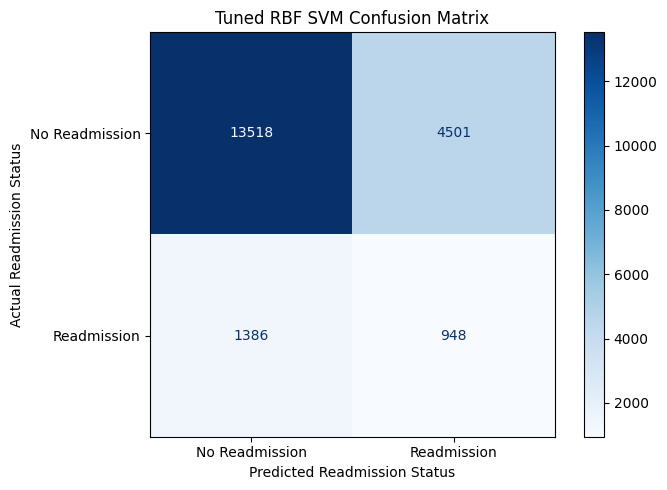

In [20]:

# 7.2 Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate confusion matrix for tuned RBF SVM
cm_tuned = confusion_matrix(
    y_test,
    y_test_pred_tuned,
    labels=[0, 1]
)

# Extract classification outcomes
tn, fp, fn, tp = cm_tuned.ravel()

print("Tuned RBF SVM Confusion Matrix:")
print(cm_tuned)

print("\nClassification Outcomes:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=[
        "No Readmission",
        "Readmission"
    ]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("Tuned RBF SVM Confusion Matrix")
ax.set_xlabel("Predicted Readmission Status")
ax.set_ylabel("Actual Readmission Status")

plt.tight_layout()
plt.show()
plt.close()



### 7.2 Analysis and Interpretation

The confusion matrix evaluates the tuned Radial Basis Function (RBF) Support Vector Machine's ability to distinguish patients who were readmitted within 30 days from those who were not readmitted.

The model correctly classified 13,518 encounters without readmission (true negatives) and correctly identified 948 encounters with readmission within 30 days (true positives).

However, the model incorrectly classified 4,501 encounters as readmissions when no readmission occurred (false positives). Additionally, 1,386 actual readmissions were incorrectly classified as non-readmissions (false negatives).

The findings indicate that the model correctly identified 40.62% of actual readmissions, consistent with the recall reported in Section 7.1. However, approximately 59.38% of actual readmissions were missed.

The 4,501 false positives also contributed to the relatively low precision of 17.40%, indicating that many encounters predicted as readmissions were not actually readmitted.

From a clinical and public health perspective, false negatives are particularly important because patients at risk of readmission may not be identified for additional monitoring or preventive interventions. False positives may also lead to unnecessary allocation of healthcare resources.

Overall, the confusion matrix demonstrates that the tuned RBF SVM correctly classifies most non-readmissions but has limited effectiveness in identifying actual readmissions. Further model improvement and evaluation are necessary before considering its application in clinical decision-making.


In [21]:

# 7.3 Identify the trained SVM model

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

print("Available SVM models and pipelines:\n")

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if isinstance(obj, SVC):
        print(
            name,
            "| Kernel:", obj.kernel,
            "| C:", obj.C,
            "| Gamma:", obj.gamma,
            "| Fitted:", hasattr(obj, "classes_")
        )

    elif isinstance(obj, Pipeline):
        print(
            name,
            "| Pipeline steps:",
            list(obj.named_steps.keys())
        )

print("\nPreviously calculated tuned scores:")

for name in list(globals()):
    if "tuned" in name.lower() or "best_svm" in name.lower():
        print(name)


Available SVM models and pipelines:

numerical_pipeline | Pipeline steps: ['imputer', 'scaler']
categorical_pipeline | Pipeline steps: ['imputer', 'encoder']
svm_rbf | Kernel: rbf | C: 1.0 | Gamma: scale | Fitted: True
svm_poly | Kernel: poly | C: 1.0 | Gamma: scale | Fitted: True
numeric_pipeline_cv | Pipeline steps: ['imputer', 'scaler']
categorical_pipeline_cv | Pipeline steps: ['imputer', 'encoder']
svm_pipeline | Pipeline steps: ['preprocessor', 'classifier']
model_gamma | Kernel: rbf | C: 0.1 | Gamma: 1.0 | Fitted: False
svm_grid | Kernel: rbf | C: 1.0 | Gamma: scale | Fitted: False
best_svm_model | Kernel: rbf | C: 1.0 | Gamma: 0.001 | Fitted: True
tuned_rbf_svm | Kernel: rbf | C: 1.0 | Gamma: 0.001 | Fitted: True

Previously calculated tuned scores:
best_svm_model
X_tuned_train
y_tuned_train
tuned_rbf_svm
y_test_pred_tuned
y_test_scores_tuned
tuned_metrics
tuned_results
cm_tuned


Tuned RBF SVM ROC-AUC: 0.6196
Number of ROC thresholds: 4041


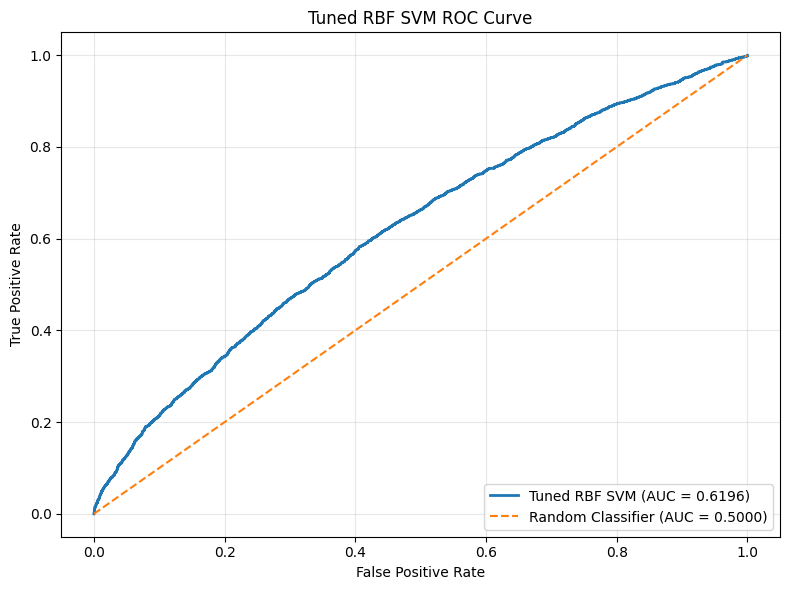

In [22]:

# 7.3 ROC Curve and ROC-AUC

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Use the previously calculated tuned model scores
fpr_tuned, tpr_tuned, thresholds_tuned = roc_curve(
    y_test,
    y_test_scores_tuned
)

# Calculate ROC-AUC
auc_tuned = roc_auc_score(
    y_test,
    y_test_scores_tuned
)

print("Tuned RBF SVM ROC-AUC:", round(auc_tuned, 4))
print("Number of ROC thresholds:", len(thresholds_tuned))

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_tuned,
    tpr_tuned,
    linewidth=2,
    label=f"Tuned RBF SVM (AUC = {auc_tuned:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier (AUC = 0.5000)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Tuned RBF SVM ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
plt.close()



### 7.3 Analysis and Interpretation

The Receiver Operating Characteristic (ROC) curve evaluates the tuned Radial Basis Function (RBF) Support Vector Machine's ability to distinguish between patients readmitted within 30 days and those who were not readmitted across different classification thresholds.

The tuned RBF SVM achieved a testing ROC-AUC of 0.6196, compared with 0.5000 for a random classifier. This indicates that the model performs better than random classification but demonstrates modest discriminatory ability.

The ROC curve remains above the diagonal reference line for most classification thresholds, indicating that the model can distinguish between the two readmission categories to some extent.

The ROC-AUC of 0.6196 also indicates that the model has approximately a 61.96% probability of assigning a higher decision score to a randomly selected readmitted encounter than to a randomly selected non-readmitted encounter.

Although hyperparameter tuning improved the RBF SVM's ROC-AUC compared with the initial RBF model (0.5983), its performance remains modest and does not exceed the baseline Linear SVM ROC-AUC of 0.6167 by a substantial margin.

From a clinical and public health perspective, the findings indicate that the tuned RBF SVM may provide some information for identifying patients at risk of hospital readmission. However, its limited discriminatory performance and relatively low recall of 0.4062 suggest that the model is not sufficiently reliable for independent clinical decision-making.

Overall, the ROC analysis demonstrates that hyperparameter optimization improved the RBF SVM's discriminatory performance, but further model development and evaluation are necessary to improve the identification of patients at risk of 30-day hospital readmission.


Week 4 vs Week 5 Model Comparison:


,Metric,Week 4 Logistic Regression,Week 5 Tuned RBF SVM
0,Accuracy,0.6191,0.7108
1,Precision,0.6449,0.1740
2,Recall,0.3864,0.4062
3,F1-Score,0.4833,0.2436
4,ROC-AUC,0.6473,0.6196


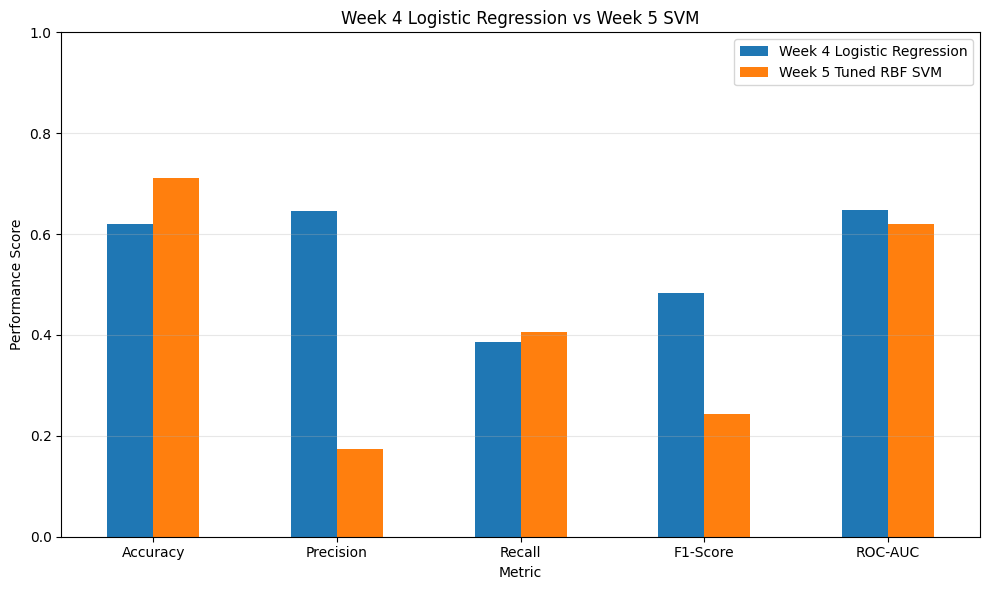

In [23]:

# 7.4 Comparison With Week 4 Logistic Regression

import pandas as pd
import matplotlib.pyplot as plt

metrics = [
    "Accuracy", "Precision", "Recall",
    "F1-Score", "ROC-AUC"
]

week4 = [0.6191, 0.6449, 0.3864, 0.4833, 0.6473]
week5 = [0.7108, 0.1740, 0.4062, 0.2436, 0.6196]

comparison = pd.DataFrame({
    "Metric": metrics,
    "Week 4 Logistic Regression": week4,
    "Week 5 Tuned RBF SVM": week5
})

print("Week 4 vs Week 5 Model Comparison:")
display(comparison.round(4))

ax = comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

plt.title("Week 4 Logistic Regression vs Week 5 SVM")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()


### 7.4 Analysis and Interpretation

The comparison between Week 4 logistic regression and Week 5 tuned RBF Support Vector Machine demonstrates differences in classification performance.

The Week 4 logistic regression model achieved an accuracy of 0.6191, precision of 0.6449, recall of 0.3864, F1-score of 0.4833, and ROC-AUC of 0.6473.

The Week 5 tuned RBF SVM achieved an accuracy of 0.7108, precision of 0.1740, recall of 0.4062, F1-score of 0.2436, and ROC-AUC of 0.6196.

The SVM achieved higher accuracy and slightly higher recall, whereas logistic regression demonstrated higher precision, F1-score, and ROC-AUC.

The ROC-AUC results suggest that logistic regression provided slightly better discrimination between the outcome classes. Although the SVM demonstrated higher overall accuracy, its relatively low precision indicates a substantial number of false-positive predictions.

These findings emphasize the importance of evaluating multiple performance metrics rather than relying exclusively on accuracy when examining hospital readmission.

However, because the models were evaluated using different testing configurations, their results should be interpreted cautiously. A direct comparison using identical outcome definitions and testing observations is necessary to determine which model performs better.


# 8. Overfitting and Generalization Assessment

## 8.1 Training and Validation Performance

### Objective

To evaluate the training and testing performance of the tuned RBF Support Vector Machine and determine whether the model demonstrates overfitting or generalizes effectively to unseen data.

### Code Explanation

The code evaluates the tuned RBF SVM using accuracy, precision, recall, F1-score, and ROC-AUC.

The training and testing scores are compared to identify performance differences. A substantially higher training performance than testing performance may indicate overfitting.

The analysis uses the previously trained model without repeating the hyperparameter grid search.


8.1 Tuned RBF SVM Performance Comparison


,Training,Testing,Train-Test Gap
Accuracy,0.7442,0.7108,0.0335
Precision,0.1992,0.1740,0.0252
Recall,0.4003,0.4062,-0.0059
F1-Score,0.2660,0.2436,0.0224
ROC-AUC,0.6553,0.6196,0.0357


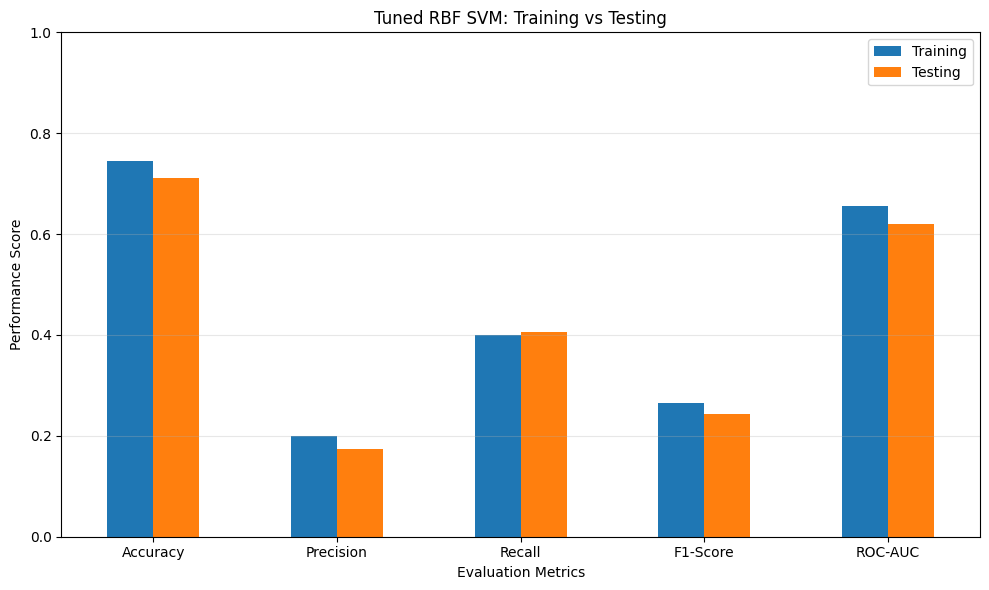

In [24]:

# 8.1 Training and Testing Performance

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Previously fitted tuned RBF SVM
model = tuned_rbf_svm

# Use the same processed feature matrices as Section 7
X_train_eval = X_tuned_train
X_test_eval = X_test_processed

# Predictions and decision scores
y_train_pred = model.predict(X_train_eval)
y_test_pred = model.predict(X_test_eval)

y_train_scores = model.decision_function(X_train_eval)
y_test_scores = model.decision_function(X_test_eval)

# Performance evaluation function
def evaluate_svm(y_true, y_pred, scores):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, scores)
    }

# Calculate performance
training_results = evaluate_svm(
    y_tuned_train, y_train_pred, y_train_scores
)

testing_results = evaluate_svm(
    y_test, y_test_pred, y_test_scores
)

# Comparison table
performance_df = pd.DataFrame({
    "Training": training_results,
    "Testing": testing_results
})

performance_df["Train-Test Gap"] = (
    performance_df["Training"] -
    performance_df["Testing"]
)

print("8.1 Tuned RBF SVM Performance Comparison")
display(performance_df.round(4))

# Visualization
performance_df[["Training", "Testing"]].plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

plt.title("Tuned RBF SVM: Training vs Testing")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
plt.close()



### 8.1 Analysis and Interpretation

The training and testing performance of the tuned RBF Support Vector Machine was evaluated using accuracy, precision, recall, F1-score, and ROC-AUC to assess overfitting and generalization.

The training accuracy was 0.7442, compared with a testing accuracy of 0.7108, resulting in a difference of approximately 0.0335. This indicates a relatively small reduction in accuracy when the model was evaluated on unseen observations.

The training precision was 0.1992, while testing precision decreased to 0.1740. Similarly, the F1-score decreased from 0.2660 during training to 0.2436 during testing.

The recall increased slightly from 0.4003 during training to 0.4062 during testing, suggesting that the model maintained a similar ability to identify actual hospital readmissions across both datasets.

The training ROC-AUC was 0.6553, compared with a testing ROC-AUC of 0.6196, representing a difference of 0.0357. This suggests a modest reduction in the model's ability to distinguish between readmitted and non-readmitted patients when applied to unseen data.

Overall, the relatively small differences between training and testing performance suggest limited evidence of severe overfitting. However, the low precision, F1-score, and moderate ROC-AUC indicate that the model's predictive performance remains limited.

These findings demonstrate that the tuned RBF SVM maintained relatively consistent performance across the training and testing datasets, although further improvements may be necessary to strengthen its usefulness for predicting hospital readmission among patients with diabetes.



## 8.2 Overfitting Prevention Strategies

### Objective

To examine the strategies used to minimize overfitting and improve the generalization performance of the tuned RBF Support Vector Machine in predicting hospital readmission among patients with diabetes.

### Code Explanation

The code summarizes the regularization and hyperparameter settings of the tuned RBF SVM and compares its training and testing performance.

The regularization parameter (C) controls the trade-off between classification errors and model complexity, while gamma determines the influence of individual training observations on the RBF decision boundary.

Cross-validation was used during hyperparameter selection to evaluate model performance across different training subsets.

The training and testing performance gaps are examined to assess whether the selected model demonstrates substantial overfitting.


8.2 Selected SVM Hyperparameters:


,Parameter,Selected Value
0,Kernel,rbf
1,Regularization (C),1.0
2,Gamma,0.001
3,Class Weight,balanced



Training and Testing Performance Gaps:


,Training,Testing,Train-Test Gap,Absolute Gap
Accuracy,0.7442,0.7108,0.0335,0.0335
Precision,0.1992,0.1740,0.0252,0.0252
Recall,0.4003,0.4062,-0.0059,0.0059
F1-Score,0.2660,0.2436,0.0224,0.0224
ROC-AUC,0.6553,0.6196,0.0357,0.0357


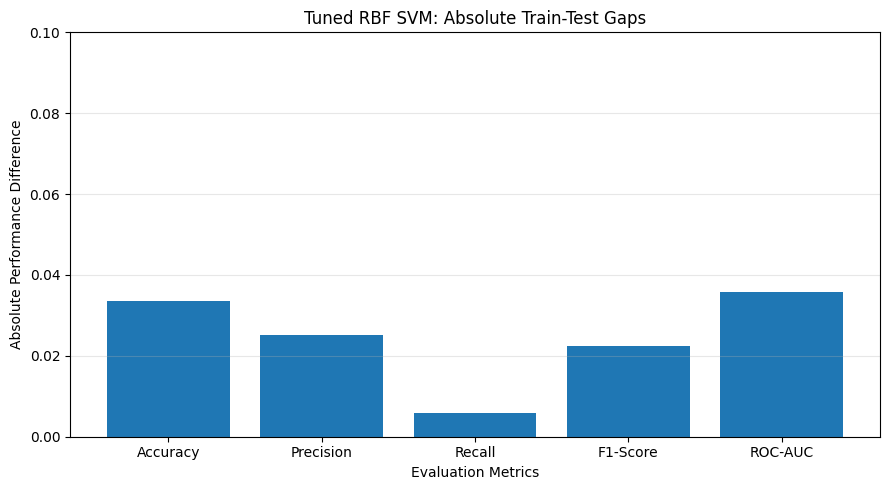


Overfitting Prevention Strategies:
1. Regularization controls model complexity.
2. Gamma controls the RBF decision boundary.
3. Cross-validation supports hyperparameter selection.
4. Training-only preprocessing reduces data leakage.
5. Held-out testing evaluates generalization.


In [25]:

# 8.2 Overfitting Prevention Strategies

import pandas as pd
import matplotlib.pyplot as plt

# Retrieve previously fitted SVM parameters
selected_parameters = {
    "Kernel": tuned_rbf_svm.kernel,
    "Regularization (C)": tuned_rbf_svm.C,
    "Gamma": tuned_rbf_svm.gamma,
    "Class Weight": tuned_rbf_svm.class_weight
}

print("8.2 Selected SVM Hyperparameters:")
display(pd.DataFrame(
    selected_parameters.items(),
    columns=["Parameter", "Selected Value"]
))

# Compare training and testing results from Section 8.1
gap_summary = performance_df.copy()

gap_summary["Absolute Gap"] = (
    gap_summary["Training"] -
    gap_summary["Testing"]
).abs()

print("\nTraining and Testing Performance Gaps:")
display(gap_summary.round(4))

# Plot absolute performance gaps
plt.figure(figsize=(9, 5))

plt.bar(
    gap_summary.index,
    gap_summary["Absolute Gap"]
)

plt.title("Tuned RBF SVM: Absolute Train-Test Gaps")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Absolute Performance Difference")
plt.ylim(0, max(0.1, gap_summary["Absolute Gap"].max() * 1.2))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
plt.close()

print("\nOverfitting Prevention Strategies:")
print("1. Regularization controls model complexity.")
print("2. Gamma controls the RBF decision boundary.")
print("3. Cross-validation supports hyperparameter selection.")
print("4. Training-only preprocessing reduces data leakage.")
print("5. Held-out testing evaluates generalization.")



### 8.2 Analysis and Interpretation

The overfitting assessment examined the training and testing performance of the tuned RBF Support Vector Machine to determine whether the model demonstrated substantial differences in predictive performance.

The selected model used an RBF kernel, regularization parameter (C) of 1.0, gamma of 0.001, and balanced class weights.

The training accuracy was 0.7442 compared with a testing accuracy of 0.7108, producing a performance gap of approximately 0.0335.

The training precision was 0.1992 compared with testing precision of 0.1740, resulting in a gap of 0.0252. The training recall was 0.4003 compared with testing recall of 0.4062, indicating a small difference of 0.0059.

Similarly, the training F1-score was 0.2660 compared with a testing F1-score of 0.2436, producing a gap of 0.0224.

The training ROC-AUC was 0.6553 compared with a testing ROC-AUC of 0.6196, resulting in the largest performance gap of 0.0357.

These relatively small training and testing differences suggest that the tuned RBF SVM did not demonstrate severe overfitting under the evaluated conditions.

Regularization and gamma tuning helped control model complexity, while cross-validation supported the selection of hyperparameters based on performance across training subsets.

However, the testing ROC-AUC of 0.6196 and precision of 0.1740 indicate that the model's ability to distinguish between readmitted and non-readmitted patients remains limited.

Overall, the findings suggest that controlling overfitting alone is insufficient to achieve strong predictive performance. Further improvements in feature selection, class imbalance management, and model development may improve hospital readmission prediction.



# 9. Discussion and Interpretation

## 9.1 Expected and Unexpected Findings

### Analysis and Interpretation

The Week 5 analysis examined the performance of Support Vector Machine (SVM) models using linear, radial basis function (RBF), and polynomial kernels to predict 30-day hospital readmission among patients with diabetes.

One expected finding was that model performance varied across the different kernel functions. The linear SVM achieved the highest accuracy of 0.6719 and ROC-AUC of 0.6167 among the three initially evaluated kernel models.

The RBF SVM demonstrated the highest recall of 0.4863, suggesting that it identified a greater proportion of patients who experienced readmission compared with the other initial SVM models.

Another expected finding was that hyperparameter tuning influenced model performance. The cross-validation grid search evaluated 16 combinations of regularization parameter (C) and gamma. The best combination was C = 1.0 and gamma = 0.001, achieving a mean cross-validation ROC-AUC of 0.6313.

An unexpected finding was that the tuned RBF SVM achieved higher testing accuracy of 0.7108 but relatively low precision of 0.1740 and F1-score of 0.2436.

The tuned model also achieved a recall of 0.4062 and ROC-AUC of 0.6196, indicating modest discrimination between readmitted and non-readmitted patients.

The confusion matrix revealed 13,518 true negatives, 4,501 false positives, 1,386 false negatives, and 948 true positives. The relatively large number of false-positive predictions demonstrated that the model frequently classified patients as readmitted when they were not.

Another important finding was the relatively small difference between training and testing performance. The training ROC-AUC was 0.6553 compared with the testing ROC-AUC of 0.6196, producing a gap of 0.0357.

These findings suggest that the tuned model did not demonstrate severe overfitting, although its predictive performance remained limited.

The comparison with Week 4 logistic regression also produced an unexpected result. Logistic regression achieved a higher ROC-AUC of 0.6473 and F1-score of 0.4833, whereas the tuned RBF SVM achieved higher accuracy and slightly higher recall.

However, the Week 4 and Week 5 models were evaluated using different testing configurations. Therefore, their performance differences should be interpreted cautiously rather than treated as a definitive comparison.

Overall, the findings demonstrate that increasing model complexity and performing hyperparameter tuning do not necessarily guarantee stronger predictive performance. Model selection should consider discrimination, precision, recall, generalization, and the clinical implications of classification errors.



## 9.2 Clinical and Public Health Implications

### Analysis and Interpretation

The findings from the Week 5 Support Vector Machine analysis have important implications for clinical decision-making, hospital readmission prevention, and public health planning among patients with diabetes.

The tuned RBF SVM achieved an accuracy of 0.7108, recall of 0.4062, precision of 0.1740, F1-score of 0.2436, and ROC-AUC of 0.6196.

These results indicate that the model demonstrated limited ability to distinguish between patients who experienced hospital readmission within 30 days and those who did not.

The confusion matrix identified 948 true positives, 13,518 true negatives, 4,501 false positives, and 1,386 false negatives.

From a clinical perspective, the 1,386 false negatives are particularly important because these patients experienced readmission but were incorrectly classified as not readmitted.

Failure to identify patients at risk of readmission could result in missed opportunities for additional discharge education, medication reconciliation, follow-up appointments, and diabetes management support.

The 4,501 false positives also have important implications for healthcare resource allocation. These patients were predicted to experience readmission even though they did not.

A large number of false-positive predictions could lead to unnecessary follow-up interventions, increased healthcare expenditures, and inefficient allocation of limited clinical resources.

From a public health perspective, predictive models could potentially support the identification of populations requiring additional diabetes management interventions, particularly when combined with clinical assessment and other relevant patient information.

Healthcare organizations could use appropriately validated risk prediction models to support discharge planning, patient education, care coordination, and targeted follow-up services.

However, the relatively low precision and modest ROC-AUC observed in this analysis suggest that the tuned RBF SVM should not be used independently to make clinical decisions.

Further model development and external validation would be necessary before considering its application in healthcare settings.

The findings also emphasize the importance of selecting evaluation metrics that reflect the consequences of classification errors. Accuracy alone may be misleading when the outcome classes are imbalanced.

Recall is particularly relevant when the objective is to identify patients at risk of readmission, while precision is important for reducing unnecessary interventions among patients who are unlikely to be readmitted.

Overall, the Week 5 analysis demonstrates the potential relevance of machine learning to diabetes-related hospital readmission research while highlighting the need for improved predictive performance, careful validation, and responsible clinical implementation.



## 9.3 Model Limitations

### Analysis and Interpretation

The Week 5 Support Vector Machine analysis demonstrated several limitations that should be considered when interpreting the model's predictive performance for 30-day hospital readmission among patients with diabetes.

One important limitation was the relatively modest discriminatory performance of the tuned RBF SVM. Although the model achieved a testing accuracy of 0.7108, its ROC-AUC of 0.6196 indicates limited ability to distinguish between readmitted and non-readmitted patients.

Another limitation was the low precision of 0.1740 and F1-score of 0.2436. These results suggest that a substantial proportion of patients predicted to experience readmission were incorrectly classified.

The confusion matrix identified 4,501 false positives and 1,386 false negatives. These classification errors could affect the usefulness of the model for clinical decision-making and healthcare resource allocation.

Class imbalance was another important consideration. The testing dataset contained 18,019 patients without readmission and 2,334 patients with readmission. This unequal distribution could influence model performance and make accuracy alone an insufficient evaluation metric.

Although balanced class weights were applied to address class imbalance, the model continued to demonstrate limited precision and recall.

The computational requirements of nonlinear SVM models also presented a limitation. The RBF and polynomial kernels required smaller training samples of 20,000 observations, whereas the linear SVM was trained using 81,413 observations.

Consequently, the differences in training sample sizes limit direct comparisons between the initial kernel models.

Another limitation was the restricted hyperparameter search. The grid search evaluated 16 combinations of regularization parameter (C) and gamma. Other parameter combinations might produce different results.

The analysis also relied on the available patient characteristics and hospitalization variables. Additional clinically relevant information, including disease severity, laboratory results, medication adherence, and post-discharge care, could potentially improve prediction if available and appropriately measured.

Furthermore, the comparison between Week 4 logistic regression and Week 5 SVM was based on different testing configurations. Therefore, the observed differences in predictive performance cannot establish that one algorithm is definitively superior.

Finally, the model was evaluated using the available diabetes hospitalization dataset without independent external validation. Its performance may differ across hospitals, patient populations, and healthcare systems.

Overall, these limitations demonstrate that the tuned RBF SVM requires further development and validation before it could be considered for clinical applications.

Future analysis could examine additional predictors, alternative methods for managing class imbalance, broader hyperparameter tuning, and consistent testing procedures to improve model performance and generalizability.



# 10. Conclusion

### Analysis and Interpretation

The Week 5 analysis examined the application of Support Vector Machines (SVMs), kernel functions, regularization, and hyperparameter tuning to predict 30-day hospital readmission among patients with diabetes.

The analysis evaluated linear, radial basis function (RBF), and polynomial SVM kernels to determine their predictive performance using accuracy, precision, recall, F1-score, and ROC-AUC.

The initial kernel comparison demonstrated differences in classification performance. The linear SVM achieved the highest accuracy of 0.6719 and ROC-AUC of 0.6167 among the three initial kernel models, while the RBF SVM achieved the highest recall of 0.4863.

Hyperparameter tuning was subsequently performed using cross-validation to evaluate 16 combinations of the regularization parameter (C) and kernel parameter (gamma).

The best-performing hyperparameter combination was C = 1.0 and gamma = 0.001, achieving a mean cross-validation ROC-AUC of 0.6313.

The tuned RBF SVM achieved a testing accuracy of 0.7108, precision of 0.1740, recall of 0.4062, F1-score of 0.2436, and ROC-AUC of 0.6196.

Although the tuned model demonstrated higher accuracy than the initial SVM models, its relatively low precision and modest ROC-AUC indicated limitations in predicting hospital readmission.

The confusion matrix identified 13,518 true negatives, 4,501 false positives, 1,386 false negatives, and 948 true positives. These results highlighted the importance of examining classification errors when evaluating predictive models for healthcare applications.

The overfitting assessment demonstrated relatively small differences between training and testing performance. The training ROC-AUC was 0.6553 compared with the testing ROC-AUC of 0.6196, suggesting that the model did not demonstrate severe overfitting under the evaluated conditions.

The comparison with Week 4 logistic regression indicated that logistic regression achieved higher precision, F1-score, and ROC-AUC, whereas the tuned RBF SVM achieved higher accuracy and slightly higher recall.

However, differences in testing configurations limited the ability to make definitive conclusions regarding the superiority of either model.

From a clinical and public health perspective, the findings demonstrated the potential relevance of machine learning for identifying patients at risk of diabetes-related hospital readmission.

Nevertheless, the model's limited discriminatory performance and substantial number of false-positive and false-negative predictions suggest that further development and validation are necessary before considering clinical implementation.

Future research could investigate additional clinical predictors, improved feature selection, alternative class imbalance management techniques, broader hyperparameter optimization, and external validation across different healthcare populations.

Overall, this analysis strengthened my understanding of Support Vector Machines, the kernel trick, regularization, hyperparameter tuning, and model evaluation in healthcare data science.

The findings emphasize that selecting an appropriate predictive model requires consideration of multiple evaluation metrics, generalization performance, and the practical consequences of classification errors rather than relying exclusively on accuracy.



# 11. References

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*, 273–297. https://doi.org/10.1007/BF00994018

Dua, D., & Graff, C. (2019). *UCI Machine Learning Repository*. University of California, Irvine. https://archive.ics.uci.edu/

Huang, J., Ling, C. X., & Zhang, J. (2012). *Diabetes 130-US Hospitals for Years 1999–2008* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

Scikit-learn developers. (n.d.). *Support vector machines*. Scikit-learn. https://scikit-learn.org/stable/modules/svm.html

Scikit-learn developers. (n.d.). *Grid search*. Scikit-learn. https://scikit-learn.org/stable/modules/grid_search.html

Scikit-learn developers. (n.d.). *Cross-validation: Evaluating estimator performance*. Scikit-learn. https://scikit-learn.org/stable/modules/cross_validation.html

Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). Impact of HbA1c measurement on hospital readmission rates: Analysis of 70,000 clinical database patient records. *BioMed Research International, 2014*, Article 781670. https://doi.org/10.1155/2014/781670



# Appendix A: Artificial Intelligence (AI) Use Disclosure

ChatGPT, developed by OpenAI, was used as a supplementary academic support tool during the preparation of this Week 5 Support Vector Machine analysis.

AI assistance included organizing the notebook, explaining Python code, supporting debugging, improving the clarity and structure of written interpretations, and assisting with the presentation of results.

AI was also used to support the explanation of Support Vector Machines, kernel functions, regularization, cross-validation, hyperparameter tuning, and model evaluation.

The analysis was conducted using the Diabetes 130-US Hospitals dataset in Google Colab. Model performance metrics, tables, and visualizations were generated through Python and scikit-learn.

The AI tool assisted with interpreting the computational outputs and organizing the findings into an academic format.

The reported numerical results were obtained from the executed notebook rather than generated or estimated by AI.

The final submission remains subject to my review and verification, including the accuracy of the code, analysis, interpretations, and references.

### AI Tool Reference

OpenAI. (2026). *ChatGPT* [Large language model]. https://chatgpt.com/
